# Card Sales Analysis: step-by-step methodology

This notebook reproduces **every number, table and chart in the Card Sales Dashboard** (`dashboard.html`) with pandas and matplotlib, one step at a time. Each step explains *what* is calculated and, in the code comments, *why* it matters for the business.

It follows the same order as the original *CC Transactions 2025* notebook:

1. **Load and select the columns**
2. **Clean:** dates, amounts, statuses, missing customer names, refunds, zero amounts, duplicates, retries
3. **Customer groups:** one business, several cards
4. **Timeframe and time buckets:** what each comparison means for this much history
5. **Headline figures (KPI tiles)**
6. **Revenue over time:** trend, % change, year over year
7. **Momentum and slowdown:** card payment breaks (the 60-day rule), customer trends, needs attention, overdue customers
8. **Customers:** top 15, concentration, average per active period, payment cadence
9. **Customer segments (RFM)**
10. **Customers starting to pay by card**
11. **Risk and operations:** failures, card mix, decline reasons, retries, voids
12. **Data quality**
13. **What changed from the original notebook, and why**

**How to run it:** put the processor's CSV export (and optionally your `customer-groups.csv` saved from the dashboard) in the same folder as this notebook, set the file names in the next cell, then *Run All*. The CSV is only read, never modified.

## 0. Setup

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.colors as mcolors
from IPython.display import display

# ---- Inputs ---------------------------------------------------------------
CSV_PATH = '../sample-data/sample_transactions.csv'   # the card processor's export (read-only)
GROUPS_PATH = '../tests/fixtures/sample_customer_groups.csv'   # optional: customer groups saved from the dashboard (None to skip)

# ---- The same controls as the dashboard's filter bar ----------------------
DATE_FROM = None          # e.g. '2025-03-01' to narrow the period; None = first transaction
DATE_TO = None            # e.g. '2025-09-30'; None = last transaction
GROUP_BY = 'auto'         # 'auto', 'day', 'week', 'month' or 'quarter' (chart grouping only)
STATUS_FILTER = 'all'     # 'all' attempts, or 'success' for successful charges only
ATTENTION_THRESHOLD = 0.25  # "Needs attention" = recent spend at least 25% below baseline
CARD_STOP_DAYS = 60       # business rule: 60+ days without a card payment = stopped paying by card

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 160)

In [2]:
# ---- Colours and chart style (the dashboard's palette) ---------------------
ACCENT, ACCENT_SOFT = '#2a78d6', '#b7d3f6'   # the one neutral data colour, and its light step
ORANGE, AQUA, GREY = '#eb6834', '#1baf7a', '#a8a7a0'
GOOD, GOOD_DEEP, BAD, BAD_DEEP, WARN = '#0ca30c', '#0a6e0a', '#d03b3b', '#a32424', '#fab219'
INK, INK2, MUTED, GRID, SURFACE = '#141413', '#52514e', '#7a7873', '#e6e5df', '#fcfcfb'
SEG_COLORS = ['#104281', '#2a78d6', '#6da7ec', '#b7d3f6']   # ordinal ramp: best segment darkest

plt.rcParams.update({
    'figure.dpi': 100, 'savefig.dpi': 100, 'figure.facecolor': 'white', 'axes.facecolor': SURFACE,
    'axes.edgecolor': '#c3c2b7', 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2, 'font.size': 10,
})

# ---- Number formatting used everywhere --------------------------------------
def money(dollars, cents=False):
    # Headline money: $1,234,567 (or $1,234.56); negatives as −$1,234.
    if dollars is None or pd.isna(dollars):
        return '—'
    s = f"${abs(dollars):,.2f}" if cents else f"${abs(round(dollars)):,.0f}"
    return ('−' if dollars < 0 and abs(dollars) >= (0.005 if cents else 0.5) else '') + s

def compact(dollars):
    # Axis/label money: $1.23M, $450K, $12.5K, $950.
    a = abs(dollars)
    if a >= 1e6: s = f"{a / 1e6:.2f}".rstrip('0').rstrip('.') + 'M'
    elif a >= 1e5: s = f"{round(a / 1e3)}K"
    elif a >= 1e3: s = f"{a / 1e3:.1f}".rstrip('0').rstrip('.') + 'K'
    else: s = f"{round(a)}"
    return ('−' if dollars < 0 and a >= 0.5 else '') + '$' + s

def pct(x, d=1):
    return '—' if x is None or pd.isna(x) else f"{x * 100:.{d}f}%"

def signed_pct(x, d=1):
    return '—' if x is None or pd.isna(x) else ('+' if x > 0 else '−' if x < 0 else '') + f"{abs(x) * 100:.{d}f}%"

money_axis = mticker.FuncFormatter(lambda v, _: compact(v))

## 1. Load the export and select the columns

The export has 35 to 117 columns depending on its age; six are used. Column names are matched **case- and punctuation-insensitively** (`Date & Time`, `date and time` and `DATE_TIME` all match) because they vary slightly between exports.

Everything is read **as text** (`dtype=str`, `keep_default_na=False`). That keeps an empty status as an empty string instead of `NaN`, and keeps amounts exactly as exported until they're validated.

In [3]:
raw = pd.read_csv(CSV_PATH, dtype=str, keep_default_na=False, encoding='utf-8-sig')
print(f"{len(raw):,} rows × {raw.shape[1]} columns read from {CSV_PATH}")

norm = lambda s: re.sub(r'[^a-z0-9]', '', str(s).lower())
ALIASES = {  # purpose: (required?, names recognised)
    'date':        (True,  ['datetime', 'dateandtime', 'transactiondate', 'transactiondatetime', 'date']),
    'customer':    (True,  ['customernumber', 'customername', 'customer', 'customerno']),  # holds the customer NAME
    'amount':      (True,  ['amount', 'amountcents', 'transactionamount']),
    'card':        (True,  ['cardtype', 'cardscheme', 'cardbrand']),
    'status':      (True,  ['status', 'transactionstatus', 'result']),
    'currency':    (False, ['currency', 'currencycode']),
    'void_note':   (False, ['voidcomment', 'voidreason']),            # explains voids (mostly $1 tests)
    'cardholder':  (False, ['cardholdersname', 'cardholdername', 'cardholder', 'nameoncard']),  # for customer groups
    'card_number': (False, ['cardnumber', 'maskedcardnumber', 'maskedpan']),                    # masked; last 4 only
}
by_norm = {}
for c in raw.columns:  # first occurrence wins (newer exports repeat names such as 'type')
    by_norm.setdefault(norm(c), c)
COLS = {k: next((by_norm[a] for a in names if a in by_norm), None) for k, (req, names) in ALIASES.items()}
missing = [k for k, (req, _) in ALIASES.items() if req and COLS[k] is None]
assert not missing, f"Missing required column(s): {missing}"
display(pd.DataFrame({'used as': list(COLS), 'column in export': [COLS[k] or '(not present)' for k in COLS]}))

2,531 rows × 35 columns read from ../sample-data/sample_transactions.csv


,used as,column in export
0,date,Date & Time
1,customer,Customer Number
2,amount,Amount
3,card,Card Type
4,status,Status
5,currency,Currency
6,void_note,Void Comment
7,cardholder,Cardholder's Name
8,card_number,Card Number


## 2. Clean

### 2.1 Dates: explicit formats only, never guessed

Older exports write `03/11/2025 14:05` (**day first**: 3 November), newer ones `2026-06-30 21:44:36` (**year first**). Each format is parsed **explicitly**. Letting pandas guess would read `03/11/2025` as 11 March in some locales and silently corrupt every trend. A month-first US date like `12/31/2025` is rejected, never swapped.

The time is kept only to order attempts made on the same day, which retry detection needs. Analysis uses the date.

In [4]:
FORMATS = [('%d/%m/%Y %H:%M', 'DD/MM/YYYY (day first)'), ('%d/%m/%Y %H:%M:%S', 'DD/MM/YYYY (day first)'),
           ('%d/%m/%Y', 'DD/MM/YYYY (day first)'), ('%Y-%m-%d %H:%M:%S', 'YYYY-MM-DD (year first)'),
           ('%Y-%m-%d %H:%M', 'YYYY-MM-DD (year first)'), ('%Y-%m-%d', 'YYYY-MM-DD (year first)')]

stamp = raw[COLS['date']].str.strip()
ts = pd.Series(pd.NaT, index=raw.index, dtype='datetime64[ns]')
date_format = pd.Series('', index=raw.index)
for fmt, label in FORMATS:
    todo = ts.isna()
    if not todo.any():
        break
    parsed = pd.to_datetime(stamp[todo], format=fmt, errors='coerce')
    ok = parsed.notna()
    ts.loc[parsed[ok].index] = parsed[ok]
    date_format.loc[parsed[ok].index] = label

bad_date = ts.isna()
print("Date formats found:", date_format[~bad_date].value_counts().to_dict())
print(f"Unreadable dates: {bad_date.sum()}")
if bad_date.any():
    display(raw.loc[bad_date, [COLS['date']]].head(10))

Date formats found: {'DD/MM/YYYY (day first)': 2531}
Unreadable dates: 0


### 2.2 Amounts are integer cents

`263391` means **$2,633.91**. Amounts are validated as whole numbers, then divided by 100. Anything with a decimal point is rejected, because it would mean the export is in dollars and dividing by 100 would be wrong. All sums below are done in **cents** (integers), so totals are exact to the cent.

In [5]:
amount_text = raw[COLS['amount']].str.strip().str.replace(r'[\s,]', '', regex=True)
bad_amount = ~amount_text.str.fullmatch(r'[-+]?\d+') & ~bad_date
cents = pd.to_numeric(amount_text.where(~bad_amount), errors='coerce')
print(f"Unreadable amounts: {bad_amount.sum()}")
(cents / 100).describe().apply(lambda v: round(v, 2)).to_frame('Amount ($)')

Unreadable amounts: 0


,Amount ($)
count,2531.00
mean,575.35
std,601.87
min,-590.71
25%,232.76
50%,338.92
75%,639.73
max,4476.22


### 2.3 Status: Batched, Failed or Voided

The original notebook converted Status with `pd.Categorical(..., categories=['Batched', 'Failed', 'Voided'])`. The processor doesn't write a plain `Failed`; it writes `Failed - Result [101] Message [Declined]` and similar. Those values aren't one of the three categories, so the categorical conversion turned **every failed charge into `NaN`**. They then looked like missing statuses. The next cell shows this happening.

Here every status is normalised explicitly:
- `Batched` = a successful charge
- **Failed** = anything starting with "Failed", or an empty status. The processor's message is kept as the **failure reason**.
- `Voided` = cancelled by an admin
- anything else is rejected and reported

In [6]:
status_raw = raw[COLS['status']].str.strip()
print("What the export actually contains:")
display(status_raw.replace('', '(blank)').value_counts().to_frame('rows'))

import warnings
with warnings.catch_warnings():          # recent pandas versions even warn that this silently drops values
    warnings.simplefilter('ignore')
    as_categorical = pd.Categorical(status_raw, categories=['Batched', 'Failed', 'Voided'])
print("What pd.Categorical makes of it (failed charges become NaN):")
display(pd.Series(as_categorical).value_counts(dropna=False).to_frame('rows'))

What the export actually contains:


,rows
Status,
Batched,2184
(blank),283
Voided,28
Failed - Result [101] Message [Declined],19
Failed - Result [101] Message [Expiry Date incorrect],9
Failed - Result [101] Message [Authorization Declined],8


What pd.Categorical makes of it (failed charges become NaN):


,rows
Batched,2184
NaN,319
Voided,28
Failed,0


In [7]:
low = status_raw.str.lower()
status = pd.Series(np.select(
    [status_raw.eq(''), low.eq('batched'), low.isin(['voided', 'void']), low.str.startswith('failed') | low.eq('declined')],
    ['Failed',          'Batched',         'Voided',                       'Failed'], default=''), index=raw.index)
# Business logic: a declined charge is a failed attempt to collect; the reason says why (card declined,
# expired, over limit...). An empty status is also an unsuccessful attempt.
message = status_raw.str.extract(r'(?i)message\s*\[([^\]]*)\]', expand=False)        # "… Message [Declined]"
rest = status_raw.str.replace(r'(?i)^failed\s*[-:]?\s*', '', regex=True)               # "Failed - <something>"
reason = pd.Series(np.where(status_raw.eq(''), 'Blank status', message.fillna(rest).str.strip()), index=raw.index)
reason = reason.where(status.eq('Failed'), '').mask(status.eq('Failed') & reason.eq(''), 'Failed')
unknown_status = status.eq('') & ~bad_date & ~bad_amount
print(f"Unrecognised statuses: {unknown_status.sum()}")
status.value_counts().to_frame('rows after normalising')

Unrecognised statuses: 0


,rows after normalising
Batched,2184
Failed,319
Voided,28


### 2.4 Assemble the clean table

**Blank customer names** are cards keyed into the terminal once and never saved against an account: a one-time payment outside the customer's usual method. They are grouped into one pseudo-customer, **One-Time Manual Charge**. It counts towards revenue but is tagged as an aggregate wherever it could rank, and it's left out of per-customer behaviour (trends, stopped paying by card, segments, acquisition).

In [8]:
ONE_TIME = 'One-Time Manual Charge'
keep = ~(bad_date | bad_amount | unknown_status)
opt = lambda key: raw[COLS[key]].str.strip() if COLS[key] else pd.Series('', index=raw.index)

df = pd.DataFrame({
    'line': raw.index + 2,                                   # CSV line number (header is line 1), for reporting
    'ts': ts, 'day': ts.dt.normalize(),
    'second': ts.dt.hour * 3600 + ts.dt.minute * 60 + ts.dt.second,  # only to order same-day attempts
    'label': raw[COLS['customer']].str.strip().str.replace(r'\s+', ' ', regex=True),
    'cents': cents, 'currency': opt('currency').str.upper().replace('', 'UNKNOWN'),
    'card': raw[COLS['card']].str.strip().str.upper().replace('', 'UNKNOWN'),
    'status': status, 'reason': reason, 'void_note': opt('void_note'),
    'cardholder': opt('cardholder').str.replace(r'\s+', ' ', regex=True),
    'last4': opt('card_number').str.extract(r'(\d{4})\s*$', expand=False).fillna(''),
    'date_format': date_format,
})[keep].copy()
blank_status_kept = (status_raw.eq('') & keep).sum()
suffixed_failed_kept = (status.eq('Failed') & status_raw.ne('') & keep).sum()
df['cents'] = df['cents'].astype('int64')
df['one_time'] = df['label'].eq('')
df.loc[df.one_time, 'label'] = ONE_TIME
df['customer'] = df['label']          # replaced by the customer group in section 3
# How each row appears in the export: its customer name, or for a manual charge its cardholder.
df['source'] = np.where(df.one_time, 'Manual charge · ' + df.cardholder, df.label)
# Exports list the newest first; analysis runs oldest first (ties keep export order).
df = df.sort_values(['day', 'second', 'line'], kind='stable').reset_index(drop=True)

print(f"{len(df):,} rows kept of {len(raw):,} | blank customer names relabelled: {df.one_time.sum()}")
display(df[['day', 'label', 'cents', 'currency', 'card', 'status', 'reason']].head())

2,531 rows kept of 2,531 | blank customer names relabelled: 8


,day,label,cents,currency,card,status,reason
0,2024-11-04,Meadow Grill Midtown,122100,CAD,VISA,Batched,
1,2024-11-04,Olive Bistro,100,CAD,VISA,Voided,
2,2024-11-04,Olive Bistro,16018,CAD,VISA,Batched,
3,2024-11-04,Maple Eatery,35259,CAD,VISA,Batched,
4,2024-11-04,Kettle Supper Club,69804,CAD,MC,Batched,


### 2.5 Refunds, zero amounts and "duplicates"

- **Negative amounts** are refunds, chargebacks or credits. They are never netted silently: *gross* revenue excludes them and *net* revenue subtracts them, so both figures are shown.
- **Zero-amount** charges shouldn't exist, so they're flagged for review, not dropped.
- **Repeated amounts are normal.** Customers order from a fixed order guide, so the same customer, amount and card type on *different* dates is a repeat order. The original notebook's duplicate check found many rows for this reason. A real duplicate needs the **same date as well, with both charges successful**. Those are listed for review and never removed automatically.

In [9]:
negatives = df[df.cents < 0]
zeros = df[df.cents == 0]
print(f"Negative amounts (refunds/credits): {len(negatives)}, total {money(negatives.cents.sum() / 100, cents=True)}")
print(f"Zero-amount transactions: {len(zeros)}")

naive = df[df.duplicated(['label', 'cents', 'card'], keep=False)]
print(f"\nSame customer + amount + card type on any date (original check): {len(naive):,} rows. Mostly repeat orders.")

Negative amounts (refunds/credits): 4, total −$1,559.33
Zero-amount transactions: 1

Same customer + amount + card type on any date (original check): 569 rows. Mostly repeat orders.


### 2.6 Retry chains: a failed charge recovered later

A failed charge is often re-attempted a day or several later for the same amount. Within each **customer + amount + card type**, rows are walked in time order. **One or more failures followed by a later success form one chain.** Only the success counts as revenue, so nothing is double-counted.

This is stricter than the original notebook's version, which only asked whether a group contained *any* failure and *any* success. A success that came *before* a failure isn't a recovery, and one group can hold several chains.

**Retry recovery rate** = failed charges followed by a matching success ÷ all failed charges.

In [10]:
def retry_chains(rows):
    # Business logic: walk each customer/amount/card's attempts in time order; failures followed by a success
    # are one recovered chain. Failures with no later success stay unrecovered.
    attempts = rows[(rows.cents > 0) & rows.status.isin(['Failed', 'Batched'])]
    chains, unrecovered, mixed_groups = [], [], 0
    for key, g in attempts.groupby(['customer', 'cents', 'card'], sort=False):
        pending = []
        if g.status.eq('Failed').any() and g.status.eq('Batched').any():
            mixed_groups += 1
        for idx, r in zip(g.index, g.itertuples()):
            if r.status == 'Failed':
                pending.append(idx)
            elif pending:
                first = rows.at[pending[0], 'day']
                chains.append({'customer': key[0], 'amount': key[1] / 100, 'card': key[2], 'attempts': len(pending) + 1,
                               'first_failure': first.date(), 'success': r.day.date(), 'days': (r.day - first).days,
                               'failure_rows': list(pending)})
                pending = []
        unrecovered += pending
    return pd.DataFrame(chains), unrecovered, mixed_groups

## 3. Customer groups: one business, several cards

The processor saves **each card on file under its own customer name**, so one business can appear several times: its own name, `<name> OTO` (a one-time-only card), `<name> 4242` (named after a card ending), or a parent company whose *cardholder* is the restaurant. If these aren't grouped, revenue is split and rankings understate the customer. A customer who switches cards also looks like one account stopping card payments while a new one starts.

**Suggestions** come from two signals in the export:
1. One name is another plus a **card tag**: `OTO`, `One Time Only`, `Temp`, `V2`, or **the last 4 digits of that name's own card**. Store numbers such as `7018` are not card endings, so they're never stripped.
2. The **cardholder** on one name is another customer's name.

Manual charges (no customer name) take part through their cardholder name. A **shared card is deliberately not a signal**, because chains pay for several separate locations with one corporate card.

Suggestions are only suggestions. The groups you confirmed are loaded from `GROUPS_PATH` and applied to every row before any calculation.

In [11]:
TAGS = [r' one time only$', r' one time$', r' onetime$', r' oto$', r' temp$', r' v\d{1,2}$']
nrm = lambda s: re.sub(r'[^a-z0-9]+', ' ', str(s).lower()).strip()

def card_tag_base(name, last4s):
    # Strip trailing card tags; a 4-digit number only when it is this name's own card ending.
    base, tags = nrm(name), []
    changed = True
    while changed and ' ' in base:
        changed = False
        for pat in TAGS:
            m = re.search(pat, base)
            if m: tags.append(m.group().strip()); base = base[:m.start()].strip(); changed = True
        m = re.search(r' (\d{4})$', base)
        if m and m.group(1) in last4s: tags.append(m.group(1)); base = base[:m.start()].strip(); changed = True
    return base, tags

def suggest_groups(rows):
    # One profile per export name; manual charges (blank name) profiled per cardholder.
    rows = rows[~rows.one_time | rows.cardholder.ne('')]
    prof = {}
    for r in rows.itertuples():
        key = r.source
        p = prof.setdefault(key, {'manual': r.one_time, 'gross': 0, 'last4s': set(), 'holders': set()})
        if r.status == 'Batched' and r.cents > 0: p['gross'] += r.cents
        if r.last4: p['last4s'].add(r.last4)
        if r.cardholder: p['holders'].add(r.cardholder)
    name_of = lambda k: k.replace('Manual charge · ', '', 1) if prof[k]['manual'] else k
    info = {k: (nrm(name_of(k)),) + card_tag_base(name_of(k), prof[k]['last4s']) for k in prof}
    parent = {k: k for k in prof}
    def find(x):
        while parent[x] != x: parent[x] = parent[parent[x]]; x = parent[x]
        return x
    by_key = {}
    for k, (n, base, _) in info.items():
        for key in {n, base}: by_key.setdefault(key, []).append(k)
    for k, (n, base, tags) in info.items():                       # rule 1: same name / name + card tag
        for o in by_key.get(base, []):
            if o == k or (prof[k]['manual'] and prof[o]['manual']): continue
            if info[o][0] == n or (tags and (info[o][0] == base or info[o][1] == base)):
                parent[find(k)] = find(o)
    for k, (n, base, _) in info.items():                          # rule 2: cardholder is another customer's name
        if prof[k]['manual']: continue
        for h in prof[k]['holders']:
            hb = card_tag_base(h, prof[k]['last4s'])[0]
            if not hb or hb in (n, base): continue                 # the cardholder just repeats the name
            for o in by_key.get(hb, []):
                if o != k and not prof[o]['manual']: parent[find(k)] = find(o)
    def base_display(k):
        # The name without its card tag, in the export's own casing ("Fig Deli OTO" → "Fig Deli").
        words, tags = name_of(k).split(), info[k][2]
        n = len(nrm(' '.join(tags)).split()) if tags else 0
        return re.sub(r'[\s\-–]+$', '', ' '.join(words[:-n])) if 0 < n < len(words) else name_of(k)
    sets = {}
    for k in prof: sets.setdefault(find(k), []).append(k)
    out = []
    for members in sets.values():
        if len(members) < 2 or all(prof[m]['manual'] for m in members): continue
        members.sort(key=lambda m: (-prof[m]['gross'], m))
        cands = {}
        for m in members:                                         # biggest name's casing wins
            if not prof[m]['manual']: cands.setdefault(info[m][1], base_display(m))
        def score(c):                                             # revenue covered by this candidate name
            return sum(prof[m]['gross'] + 1 for m in members if info[m][0] == c or info[m][0].startswith(c + ' '))
        name = max(cands.items(), key=lambda kv: (score(kv[0]), -len(kv[1])))[1]
        out.append({'suggested name': name, 'names in export': ' + '.join(members),
                    'revenue': sum(prof[m]['gross'] for m in members) / 100})
    cols = ['suggested name', 'names in export', 'revenue']
    return pd.DataFrame(out, columns=cols).sort_values('revenue', ascending=False, ignore_index=True)

suggestions = suggest_groups(df)
print(f"{len(suggestions)} suggested groups in this export:")
display(suggestions.assign(revenue=suggestions.revenue.map(money)))

2 suggested groups in this export:


,suggested name,names in export,revenue
0,Northwind Eatery,Northwind Eatery + Northwind Eatery OTO + Nort...,"$30,990"
1,Ember Kitchen,Ember Kitchen + Harbourline Hospitality One Ti...,"$24,866"


In [12]:
# Load the groups you confirmed in the dashboard (Customer groups → Save groups file).
group_by_name, group_by_cardholder = {}, {}
try:
    if GROUPS_PATH:
        g = pd.read_csv(GROUPS_PATH, dtype=str, keep_default_na=False, encoding='utf-8-sig')
        gc = {nrm(c): c for c in g.columns}
        holder_col = next((c for k, c in gc.items() if k.startswith('cardholder')), None)
        for _, r in g.iterrows():
            name, grp = r[gc['customer number']].strip(), r[gc['group as']].strip()
            holder = r[holder_col].strip() if holder_col else ''
            if grp and name: group_by_name[name] = grp
            elif grp and holder: group_by_cardholder[holder] = grp
except FileNotFoundError:
    print(f"No groups file at {GROUPS_PATH}: every export name is its own customer.")

# Business logic: map each export name to the customer it belongs to; a manual charge whose cardholder
# is assigned moves out of the one-time aggregate into that customer.
named = ~df.one_time
df.loc[named, 'customer'] = df.loc[named, 'label'].map(lambda c: group_by_name.get(c, c))
manual_hit = df.one_time & df.cardholder.isin(list(group_by_cardholder))
df.loc[manual_hit, 'customer'] = df.loc[manual_hit, 'cardholder'].map(group_by_cardholder)
df.loc[manual_hit, 'one_time'] = False

print(f"Groups loaded: {len(set(group_by_name.values()) | set(group_by_cardholder.values()))} customers covering "
      f"{len(group_by_name)} names and {len(group_by_cardholder)} manual-charge cardholders")
print(f"Customers before grouping: {df.loc[df.label.ne(ONE_TIME), 'label'].nunique()} → after: {df.loc[~df.one_time, 'customer'].nunique()}"
      f" | manual charges assigned to a customer: {manual_hit.sum()}")
members = df[~df.one_time].groupby('customer').source.unique()
members = members[members.map(len) > 1]
display(members.map(lambda a: ' + '.join(sorted(a))).to_frame('names combined into one customer'))

Groups loaded: 2 customers covering 5 names and 1 manual-charge cardholders


Customers before grouping: 128 → after: 125 | manual charges assigned to a customer: 2


,names combined into one customer
customer,
Ember Kitchen,Ember Kitchen + Harbourline Hospitality One Ti...
Northwind Eatery,Manual charge · Northwind Eatery Temp + Northw...


## 4. Timeframe and time buckets

**Chart grouping** follows the span of the data:

| span (first to last day) | ≤ 60 days | 61–183 days | 184 days – 5 years | 5 years + |
|---|---|---|---|---|
| bars are | daily | weekly (Monday start) | monthly | quarterly |

**Comparisons** follow a *timeframe* chosen from the same span. Customers order in roughly weekly rhythms: in real exports ~75% order at least every 14 days and ~95% at least every 35. So customers are tracked in whole weeks or months, and the windows grow with the history available:

| timeframe | span | KPI tiles compare | customers tracked by | needs attention baseline | "started paying by card" |
|---|---|---|---|---|---|
| a few weeks | ≤ 45 days | last 7 days vs 7 before | 7-day blocks back from the last day | previous 2 weeks | can't be told apart |
| a few months | 46–183 | last 28 (14, 7) days vs same before | 7-day blocks | previous 4 weeks | after 35 days |
| about a year | 184–395 | last full month vs month before | complete months | previous 3 months | after 45 days |
| more than a year | 396 + | last full month vs **same month a year earlier** | complete months, trend over last 12 | **same 3 months a year earlier** | after 45 days |

One rule doesn't change with the timeframe: **60+ days without a card payment means the customer has stopped paying by card** (section 7.1). An export of 60 days or less is too short to show it.

A bucket is **partial** when the selected range doesn't cover all of it. For example, an export that starts on 6 January has a partial January. Partial buckets are hatched in charts and skipped in comparisons, so a 28-day month doesn't look like a slowdown.

In [13]:
date_from = pd.Timestamp(DATE_FROM) if DATE_FROM else df.day.min()
date_to = pd.Timestamp(DATE_TO) if DATE_TO else df.day.max()
span_days = (date_to - date_from).days + 1

TIMEFRAMES = [  # key, max days, label, tracking period, comparison, recent/base periods, trend minimums, settling-in days
    dict(key='short',  max_days=45,     label='a few weeks',      period='week',  compare='trailing', compare_days=[7],
         recent=2, base=2, trend_min=3, trend_active=2, warmup=None, trend_max=None, yoy=False),
    dict(key='medium', max_days=183,    label='a few months',     period='week',  compare='trailing', compare_days=[28, 14, 7],
         recent=4, base=4, trend_min=4, trend_active=3, warmup=35, trend_max=None, yoy=False),
    dict(key='long',   max_days=395,    label='about a year',     period='month', compare='month',
         recent=3, base=3, trend_min=4, trend_active=3, warmup=45, trend_max=None, yoy=False),
    dict(key='multi',  max_days=10**9,  label='more than a year', period='month', compare='yoy',
         recent=3, base=3, trend_min=4, trend_active=3, warmup=45, trend_max=12, yoy=True),
]
TF = next(t for t in TIMEFRAMES if span_days <= t['max_days'])
UNIT = GROUP_BY if GROUP_BY != 'auto' else ('day' if span_days <= 60 else 'week' if span_days <= 183 else 'month' if span_days < 1826 else 'quarter')
FREQ = {'day': 'D', 'week': 'W-SUN', 'month': 'M', 'quarter': 'Q'}[UNIT]
ROLLING = {'day': 7, 'week': 4, 'month': 3, 'quarter': 4}[UNIT]

def short_label(p, unit=UNIT):
    s = p.start_time
    return {'day': f"{s.day} {s:%b}", 'week': f"{s.day} {s:%b} '{s:%y}", 'month': f"{s:%b} '{s:%y}",
            'quarter': f"Q{p.quarter} '{s:%y}"}[unit]

periods = pd.period_range(date_from.to_period(FREQ), date_to.to_period(FREQ), freq=FREQ)
buckets = pd.DataFrame({'period': periods, 'start': [p.start_time.normalize() for p in periods],
                        'end': [p.end_time.normalize() for p in periods]})
buckets['label'] = [short_label(p) for p in periods]
buckets['partial'] = (buckets.start < date_from) | (buckets.end > date_to) if UNIT != 'day' else False
buckets['label'] = np.where(buckets.partial, buckets.label + '*', buckets.label)
complete = buckets.index[~buckets.partial].tolist()

# The scope every calculation uses: the selected date range, optionally successful charges only.
scope = df[(df.day >= date_from) & (df.day <= date_to)]
if STATUS_FILTER == 'success':
    scope = scope[scope.status.eq('Batched')]
sales = scope[scope.status.eq('Batched') & (scope.cents > 0)]        # revenue rows
refunds = scope[scope.status.eq('Batched') & (scope.cents < 0)]      # credits / chargebacks
attempts = scope[scope.cents >= 0]                                   # charge attempts (refunds aren't attempts)
failed = attempts[attempts.status.eq('Failed')]
voided = scope[scope.status.eq('Voided')]
bucket_of = lambda days: pd.Index(buckets.period).get_indexer(days.dt.to_period(FREQ))

print(f"Range {date_from:%d %b %Y} – {date_to:%d %b %Y} = {span_days} days → timeframe '{TF['label']}', charts by {UNIT}")
print(f"{len(buckets)} buckets, {len(complete)} complete; partial: {buckets.loc[buckets.partial, 'label'].tolist() or 'none'}")

Range 04 Nov 2024 – 29 Oct 2025 = 360 days → timeframe 'about a year', charts by month
12 buckets, 10 complete; partial: ["Nov '24*", "Oct '25*"]


## 5. Headline figures (KPI tiles)

| tile | calculation | business meaning |
|---|---|---|
| Gross revenue | Σ successful (Batched) charges > 0 | what was actually collected, before refunds |
| Net revenue | gross − refunds | what was kept |
| Transactions | number of successful charges | volume of paid orders |
| Average transaction | gross ÷ transactions | typical order size |
| Active customers | named customers with ≥ 1 successful charge | breadth of the paying base (one-time charges shown separately) |
| Success rate | successful ÷ all attempts (Batched + Failed + Voided) | how often a charge goes through first time |
| Retry recovery rate | recovered failures ÷ all failures | how much declined money was eventually collected |
| Voided amount | Σ voided charges | admin cancellations (mostly $1 card tests) |

The **change** on each tile compares two equal windows chosen by the timeframe (section 4). Rates change in percentage points (pp).

Tiles compare: Sep '25 vs Aug '25  (01 Sep 2025–30 Sep 2025 vs 01 Aug 2025–31 Aug 2025)


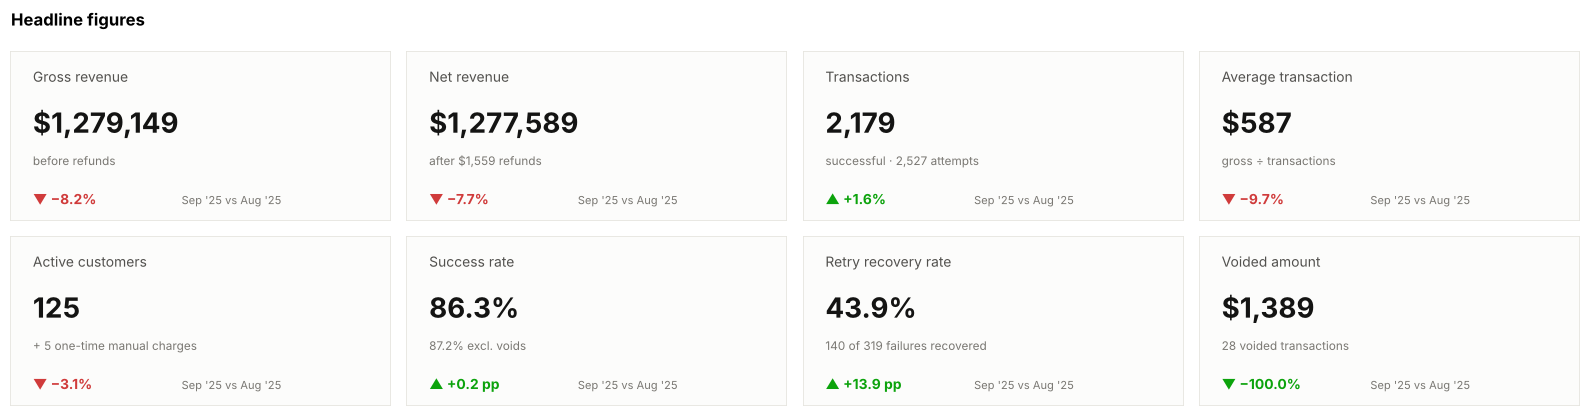

In [14]:
chains, unrecovered, mixed_groups = retry_chains(scope)
recovered_rows = set(i for rows in (chains.failure_rows if len(chains) else []) for i in rows)

def window_stats(a, b):
    # All tile metrics for days a..b (inclusive).
    w = lambda x: x[(x.day >= a) & (x.day <= b)]
    s, at, fl = w(sales), w(attempts), w(failed[failed.cents > 0])
    g = s.cents.sum()
    return {'gross': g, 'net': g + w(refunds).cents.sum(), 'count': len(s), 'avg': g / len(s) if len(s) else np.nan,
            'activeCustomers': s.loc[~s.one_time, 'customer'].nunique(),
            'successRate': at.status.eq('Batched').mean() if len(at) else np.nan,
            'recoveryRate': fl.index.isin(list(recovered_rows)).mean() if len(fl) else np.nan,
            'voidCents': w(voided).cents.sum()}

totals = window_stats(date_from, date_to)
totals['successRateExVoids'] = attempts.status.eq('Batched').sum() / attempts.status.ne('Voided').sum()

# The comparison windows for this timeframe.
months_whole = [p for p in pd.period_range(date_from.to_period('M'), date_to.to_period('M'), freq='M')
                if p.start_time.normalize() >= date_from and p.end_time.normalize() <= date_to]
compare = None
if TF['compare'] == 'trailing':
    W = next((d for d in TF['compare_days'] if 2 * d <= span_days), None)
    if W:
        n = '7 days' if W == 7 else f"{W // 7} weeks"
        compare = dict(label=f"Last {n} vs previous {n}", a=(date_to - pd.Timedelta(days=W - 1), date_to),
                       b=(date_to - pd.Timedelta(days=2 * W - 1), date_to - pd.Timedelta(days=W)))
elif len(months_whole) >= 2:
    last = months_whole[-1]
    other = last - 12 if TF['compare'] == 'yoy' and (last - 12) in months_whole else months_whole[-2]
    span_of = lambda p: (p.start_time.normalize(), p.end_time.normalize())
    compare = dict(label=last.strftime("%b '%y") + ' vs ' + other.strftime("%b '%y"), a=span_of(last), b=span_of(other))

if compare:
    A, B = window_stats(*compare['a']), window_stats(*compare['b'])
    def change(k):
        if k in ('successRate', 'recoveryRate'):
            return A[k] - B[k]                                   # percentage points
        return (A[k] - B[k]) / abs(B[k]) if B[k] else np.nan
    print(f"Tiles compare: {compare['label']}  ({compare['a'][0]:%d %b %Y}–{compare['a'][1]:%d %b %Y} vs {compare['b'][0]:%d %b %Y}–{compare['b'][1]:%d %b %Y})")

tiles = [  # key, label, value text, subtitle, is "up" good?
    ('gross', 'Gross revenue', money(totals['gross'] / 100), 'before refunds', True),
    ('net', 'Net revenue', money(totals['net'] / 100), f"after {money(-refunds.cents.sum() / 100)} refunds", True),
    ('count', 'Transactions', f"{totals['count']:,}", f"successful · {len(attempts):,} attempts", True),
    ('avg', 'Average transaction', money(totals['avg'] / 100), 'gross ÷ transactions', True),
    ('activeCustomers', 'Active customers', f"{totals['activeCustomers']:,}", f"+ {sales.one_time.sum()} one-time manual charges", True),
    ('successRate', 'Success rate', pct(totals['successRate']), f"{pct(totals['successRateExVoids'])} excl. voids", True),
    ('recoveryRate', 'Retry recovery rate', pct(totals['recoveryRate']), f"{len(recovered_rows)} of {len(failed[failed.cents > 0])} failures recovered", True),
    ('voidCents', 'Voided amount', money(totals['voidCents'] / 100), f"{len(voided)} voided transactions", False),
]
fig, axes = plt.subplots(2, 4, figsize=(16, 4.2))
for ax, (k, label, value, sub, up) in zip(axes.flat, tiles):
    ax.set_axis_off()
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, transform=ax.transAxes, facecolor=SURFACE, edgecolor=GRID, lw=1.2))
    ax.text(0.06, 0.82, label, color=INK2, fontsize=10, transform=ax.transAxes)
    ax.text(0.06, 0.52, value, color=INK, fontsize=20, fontweight='bold', transform=ax.transAxes)
    ax.text(0.06, 0.33, sub, color=MUTED, fontsize=8.5, transform=ax.transAxes)
    if compare:
        c = change(k)
        if pd.notna(c):
            txt = (f"{'+' if c > 0 else '−'}{abs(c) * 100:.1f} pp" if k in ('successRate', 'recoveryRate') else signed_pct(c))
            col = GOOD if (c > 0) == up else BAD
            ax.text(0.06, 0.1, ('▲ ' if c > 0 else '▼ ') + txt, color=col, fontsize=10, fontweight='bold', transform=ax.transAxes)
        ax.text(0.45, 0.1, compare['label'], color=MUTED, fontsize=8, transform=ax.transAxes)
fig.suptitle('Headline figures', x=0.01, ha='left', fontweight='bold')
plt.tight_layout(); plt.show()

## 6. Revenue over time

### 6.1 Revenue per period with a rolling average

Each bar is a period's **gross revenue from successful charges**. The dark line is the rolling average (7 days, 4 weeks, 3 months or 4 quarters), which smooths noise so the direction is easier to see. It's only drawn where every period in the window is complete. The highest and lowest **complete** periods are annotated, and hatched bars marked `*` are partial.

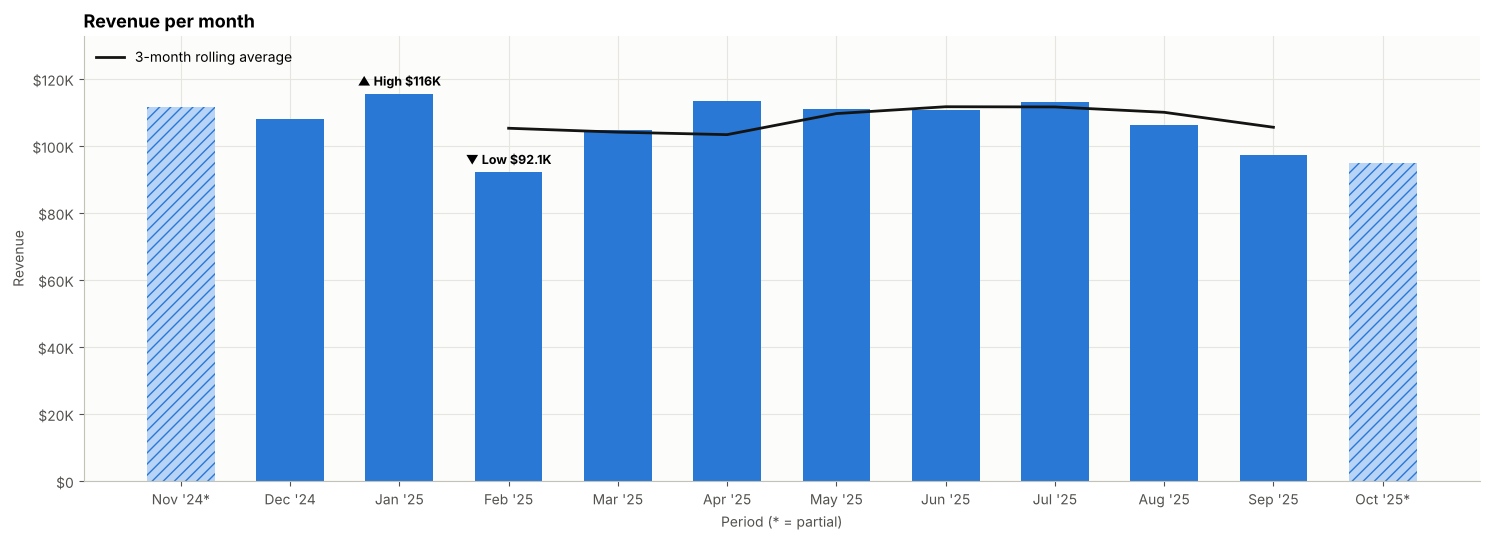

Highest complete month: Jan '25 ($115,542); lowest: Feb '25 ($92,143)


In [15]:
buckets['gross'] = np.bincount(bucket_of(sales.day), weights=sales.cents, minlength=len(buckets)).astype('int64')
buckets['charges'] = np.bincount(bucket_of(sales.day), minlength=len(buckets))
g = buckets.gross / 100

# Rolling average over complete buckets only (a partial period would drag it down).
roll = [g.iloc[i - ROLLING + 1:i + 1].mean() if i >= ROLLING - 1 and not buckets.partial.iloc[i - ROLLING + 1:i + 1].any() else np.nan
        for i in range(len(buckets))]
hi = g[complete].idxmax() if complete else None
lo = g[complete].idxmin() if complete else None

fig, ax = plt.subplots(figsize=(15, 5.5))
x = np.arange(len(buckets))
bars = ax.bar(x, g, width=0.62, color=[ACCENT_SOFT if p else ACCENT for p in buckets.partial],
              hatch=['///' if p else '' for p in buckets.partial], edgecolor=[ACCENT if p else ACCENT for p in buckets.partial], linewidth=0)
ax.plot(x, roll, color=INK, lw=2, label=f"{ROLLING}-{UNIT} rolling average")
for i, tag in ((hi, '▲ High'), (lo, '▼ Low')):
    if i is not None:
        ax.annotate(f"{tag} {compact(g[i])}", (i, g[i]), xytext=(0, 6), textcoords='offset points', ha='center', fontweight='bold', fontsize=9)
ax.set_xticks(x, buckets.label, rotation=0 if len(x) <= 14 else 45, ha='center' if len(x) <= 14 else 'right')
ax.yaxis.set_major_formatter(money_axis); ax.set_ylabel('Revenue'); ax.set_xlabel('Period (* = partial)')
ax.set_ylim(0, g.max() * 1.15); ax.legend(loc='upper left', frameon=False)
ax.set_title(f"Revenue per {UNIT}")
plt.tight_layout(); plt.show()
print(f"Highest complete {UNIT}: {buckets.label[hi]} ({money(g[hi])}); lowest: {buckets.label[lo]} ({money(g[lo])})")

### 6.2 % change against a comparable earlier period

A run of red bars is a **slowdown** even when the level still looks healthy. Each period is compared with a comparable earlier one:
- **daily bars:** the *same weekday a week earlier*, because a quiet Sunday would otherwise look like a collapse;
- **more than a year of data:** the *same month (or quarter) a year earlier*, so seasonality cancels out;
- **otherwise:** the period before.

Comparisons involving a partial period are skipped.

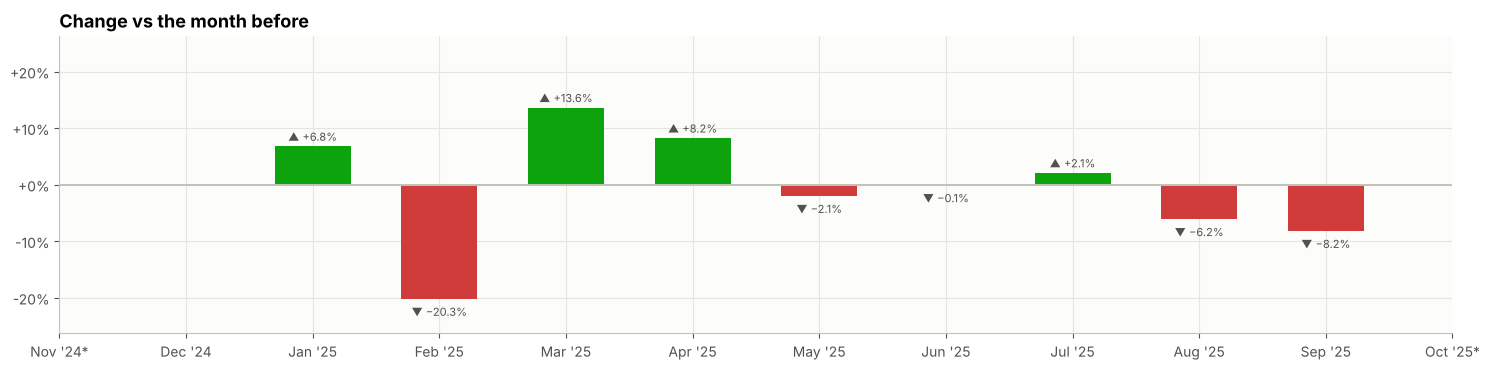

4 of 9 comparisons were up.


In [16]:
LAG = 7 if UNIT == 'day' else (12 if TF['yoy'] and UNIT == 'month' else 4 if TF['yoy'] and UNIT == 'quarter' else 1)
against = {7: 'the same weekday a week earlier', 12: 'the same month a year earlier', 4: 'the same quarter a year earlier'}.get(LAG, f"the {UNIT} before")
pop = pd.Series([np.nan] * len(buckets))
for i in range(LAG, len(buckets)):
    j = i - LAG
    if not buckets.partial[i] and not buckets.partial[j] and buckets.gross[j] != 0:
        pop[i] = (buckets.gross[i] - buckets.gross[j]) / buckets.gross[j]

fig, ax = plt.subplots(figsize=(15, 3.8))
ax.bar(x, pop * 100, width=0.6, color=[GOOD if v >= 0 else BAD for v in pop.fillna(0)])
for i, v in pop.dropna().items():
    ax.annotate(f"{'▲ +' if v >= 0 else '▼ −'}{abs(v) * 100:.1f}%", (i, v * 100), xytext=(0, 4 if v >= 0 else -12),
                textcoords='offset points', ha='center', fontsize=8, color=INK2)
ax.axhline(0, color='#c3c2b7', lw=1.4)
ax.set_xticks(x, buckets.label, rotation=0 if len(x) <= 14 else 45, ha='center' if len(x) <= 14 else 'right')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:+.0f}%"))
ax.set_title(f"Change vs {against}")
lim = max(10, np.nanmax(np.abs(pop * 100)) * 1.3) if pop.notna().any() else 10
ax.set_ylim(-lim, lim)
plt.tight_layout(); plt.show()
print(f"{(pop > 0).sum()} of {pop.notna().sum()} comparisons were up.")

### 6.3 Year over year (exports covering more than a year)

One line per calendar year across Jan–Dec, with annual totals for complete years and a year-to-date comparison. This view is how seasonality and real growth are told apart. It only appears when the export covers more than about 13 months.

In [17]:
if TF['yoy']:
    m = sales.groupby(sales.day.dt.to_period('M')).cents.sum()
    grid = pd.DataFrame(index=range(1, 13))
    for y in sorted({p.year for p in pd.period_range(date_from.to_period('M'), date_to.to_period('M'), freq='M')}):
        grid[y] = [m.get(pd.Period(f"{y}-{mm:02d}", 'M'), 0) / 100 if pd.Period(f"{y}-{mm:02d}", 'M') in months_whole else np.nan for mm in range(1, 13)]
    fig, ax = plt.subplots(figsize=(13, 4.8))
    palette = [ACCENT, ORANGE, AQUA]
    for rank, y in enumerate(reversed(grid.columns)):
        ax.plot(range(1, 13), grid[y], marker='o', lw=2.5 if rank == 0 else 2, color=palette[rank] if rank < 3 else GREY,
                label=str(y) + ('' if grid[y].notna().all() else ' (part)'))
    ax.set_xticks(range(1, 13), ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
    ax.yaxis.set_major_formatter(money_axis); ax.set_ylim(0); ax.legend(frameon=False); ax.set_title('Year over year')
    plt.tight_layout(); plt.show()
    totals_y = grid.sum(min_count=12).where(grid.notna().all())
    display(pd.DataFrame({'revenue': totals_y.map(money), 'vs previous year': totals_y.pct_change(fill_method=None).map(signed_pct)}))
else:
    print(f"This export covers {span_days} days, so there is no year-over-year view (it needs more than ~13 months).")

This export covers 360 days, so there is no year-over-year view (it needs more than ~13 months).


## 7. Momentum and slowdown

Customers are tracked in **7-day blocks counted back from the last day** (so every block is complete), or in **complete calendar months**, depending on the timeframe. Each named customer gets a revenue series over those periods.

In [18]:
if TF['period'] == 'week':
    K = span_days // 7
    track = pd.DataFrame({'end': [date_to - pd.Timedelta(days=7 * k) for k in range(K - 1, -1, -1)]})
    track['start'] = track.end - pd.Timedelta(days=6)
    track['label'] = [f"{s.day}–{e.day} {e:%b}" if s.month == e.month else f"{s.day} {s:%b}–{e.day} {e:%b}" for s, e in zip(track.start, track.end)]
else:
    track = pd.DataFrame({'start': [p.start_time.normalize() for p in months_whole], 'end': [p.end_time.normalize() for p in months_whole],
                          'label': [p.strftime("%b '%y") for p in months_whole]})
P = len(track)

def period_index(day):
    # -1 before the first period, P after the last, else the period containing the day.
    if not P or day < track.start.iloc[0]: return -1
    i = int(track.start.searchsorted(day, side='right')) - 1
    return i if day <= track.end.iloc[i] else P

named_sales = sales[~sales.one_time]
pidx = named_sales.day.map(period_index)
inside = named_sales[(pidx >= 0) & (pidx < P)]
series = (inside.assign(p=pidx[inside.index]).pivot_table(index='customer', columns='p', values='cents', aggfunc='sum', fill_value=0)
          .reindex(columns=range(P), fill_value=0).reindex(named_sales.customer.unique(), fill_value=0))
first_day = named_sales.groupby('customer').day.min()
print(f"{P} tracking {TF['period']}s ({track.label.iloc[0]} → {track.label.iloc[-1]}), {len(series)} named customers" if P
      else "No complete tracking period in this range.")

10 tracking months (Dec '24 → Sep '25), 125 named customers


### 7.1 Card payment breaks: the 60-day rule

This export only shows **card** payments, so a customer who stops appearing hasn't necessarily stopped buying. The business rule:

- **No successful card payment for 60+ days, up to the end of the range → stopped paying by card**, *as of their last card payment*. This almost always means the account moved to **EFT** or another payment method, and occasionally that it stopped trading. It is recorded as a date, not counted as a slump or as lost revenue.
- **60+ days between two card payments → a spell off card.** The customer paid another way for a while and came back. It's rare, but it happens. Tracking periods that fall **wholly inside** such a break are **skipped** in the trend and in Needs attention rather than counted as $0.
- **Shorter silences stay in play.** A customer who is late against their own usual gap but under 60 days is **overdue** (7.4): that's the list worth a call.

Gaps are measured in days between distinct card-payment days. "Days since" counts from the last card payment to the end of the range.

In [19]:
# Distinct card-payment days per customer.
pay_days = {c: d.drop_duplicates().sort_values().tolist() for c, d in named_sales.groupby('customer').day}

# Breaks: 60+ days between two consecutive card payments = paid another way for a while.
breaks = {c: [(a, b) for a, b in zip(d, d[1:]) if (b - a).days >= CARD_STOP_DAYS] for c, d in pay_days.items()}

# Stopped: 60+ days from the last card payment to the end of the range.
# Business logic: presume EFT / another method (or no longer trading) and record the date, not a churn alarm.
cust_cents = named_sales.groupby('customer').cents.agg(['sum', 'size'])
stopped = pd.DataFrame([{'customer': c, 'stopped paying by card as of': d[-1], 'days since': (date_to - d[-1]).days,
                         'card revenue to then': cust_cents.loc[c, 'sum'] / 100, 'card payments': int(cust_cents.loc[c, 'size'])}
                        for c, d in pay_days.items() if (date_to - d[-1]).days >= CARD_STOP_DAYS],
                       columns=['customer', 'stopped paying by card as of', 'days since', 'card revenue to then', 'card payments'])
stopped = stopped.set_index('customer').sort_values('card revenue to then', ascending=False)
stopped_set = set(stopped.index)

# Back on card: had a break, paid by card again afterwards, and hasn't stopped since.
back = pd.DataFrame([{'customer': c, 'off card from': b[-1][0], 'back on card': b[-1][1], 'days off card': (b[-1][1] - b[-1][0]).days}
                     for c, b in breaks.items() if b and c not in stopped_set],
                    columns=['customer', 'off card from', 'back on card', 'days off card']).set_index('customer')

def off_card(cust, i):
    # A tracking period counts as off card when it lies wholly inside one of the customer's breaks.
    s0, s1 = track.start.iloc[i], track.end.iloc[i]
    return any(a < s0 and s1 < b for a, b in breaks.get(cust, []))

if span_days <= CARD_STOP_DAYS:
    print(f"This export covers {span_days} days, so nobody can have gone {CARD_STOP_DAYS} days without a card payment yet.")
else:
    print(f"Stopped paying by card (no card payment since {date_to - pd.Timedelta(days=CARD_STOP_DAYS - 1):%d %b %Y}): "
          f"{len(stopped)} customers, {money(stopped['card revenue to then'].sum())} of card revenue in this range")
    display(stopped.assign(**{'stopped paying by card as of': stopped['stopped paying by card as of'].dt.strftime('%d %b %Y'),
                              'card revenue to then': stopped['card revenue to then'].map(money)}).head(25))
print(f"Back on card after a break of {CARD_STOP_DAYS}+ days: {len(back)} customers")
if len(back):
    display(back.assign(**{k: back[k].dt.strftime('%d %b %Y') for k in ['off card from', 'back on card']}))

Stopped paying by card (no card payment since 31 Aug 2025): 15 customers, $135,981 of card revenue in this range


,stopped paying by card as of,days since,card revenue to then,card payments
customer,,,,
Ironwood Grill,30 Aug 2025,60,"$53,269",32
Granite Bistro,23 Aug 2025,67,"$14,509",5
Ember Supper Club,01 Jul 2025,120,"$13,433",27
Kettle Canteen Midtown,06 Aug 2025,84,"$12,374",3
Maple Kitchen Uptown,09 Apr 2025,203,"$9,303",9
Wildflower Brasserie,05 Jul 2025,116,"$9,192",12
Silverbirch Grill Lakeshore,14 Jun 2025,137,"$7,019",13
Juniper Noodle House,27 Jun 2025,124,"$5,378",13
Maple Pizzeria,23 Aug 2025,67,"$3,715",5


Back on card after a break of 60+ days: 26 customers


,off card from,back on card,days off card
customer,,,
Bramble Deli,16 Jun 2025,21 Aug 2025,66
Cedar Café Uptown,04 Jul 2025,27 Sep 2025,85
Cobalt Canteen,13 Feb 2025,05 May 2025,81
Cobalt Supper Club,23 Apr 2025,06 Oct 2025,166
Copper Café,01 Apr 2025,21 Jun 2025,81
Ember Pizzeria,04 Jun 2025,02 Sep 2025,90
Golden Noodle House Harbourfront,18 Jan 2025,27 Mar 2025,68
Kettle Supper Club,21 Jul 2025,07 Oct 2025,78
Lantern Deli,11 Jun 2025,20 Sep 2025,101


### 7.2 Customer trend: linear slope ($ per week or month)

For each customer, an ordinary least-squares line is fitted to revenue per period, **starting from their first period with us**. Without that, a customer who joined in month 9 would be fitted with eight leading zeros and look like fast growth. A period with no purchase counts as $0, because not buying is information. The exception is a period spent **wholly off card** (7.1): it is skipped, because the customer was paying another way.

**Customers who stopped paying by card get no trend.** Their slide to $0 is a change of payment method, not a decline.

This replaces the original notebook's `scipy.stats.linregress`, which only used months *with* purchases and so hid gaps. `np.polyfit(x, y, 1)` gives the same slope as `linregress` on the same points.

Multi-year exports use the last 12 months, so the trend reflects current direction.

In [20]:
t0 = max(0, P - TF['trend_max']) if TF['trend_max'] else 0
slopes = {}
if P - t0 >= TF['trend_min']:
    for cust, row in series.iterrows():
        f = period_index(first_day[cust])
        if f >= P or cust in stopped_set: continue                         # stopped paying by card: no trend
        xs = [i for i in range(max(t0, f, 0), P) if not off_card(cust, i)]  # skip periods spent off card
        ys = row.values[xs].astype(float)
        if len(ys) < TF['trend_min'] or (ys > 0).sum() < TF['trend_active']: continue
        slopes[cust] = np.polyfit(np.array(xs, dtype=float), ys, 1)[0] / 100      # $ per period
slopes = pd.Series(slopes, dtype=float).sort_values(ascending=False)
print(f"{TF['period'].title()}ly trend for {len(slopes)} customers ({track.label.iloc[t0]} → {track.label.iloc[-1]}): "
      f"{(slopes > 0).sum()} growing, {(slopes < 0).sum()} declining")

Monthly trend for 98 customers (Dec '24 → Sep '25): 52 growing, 46 declining


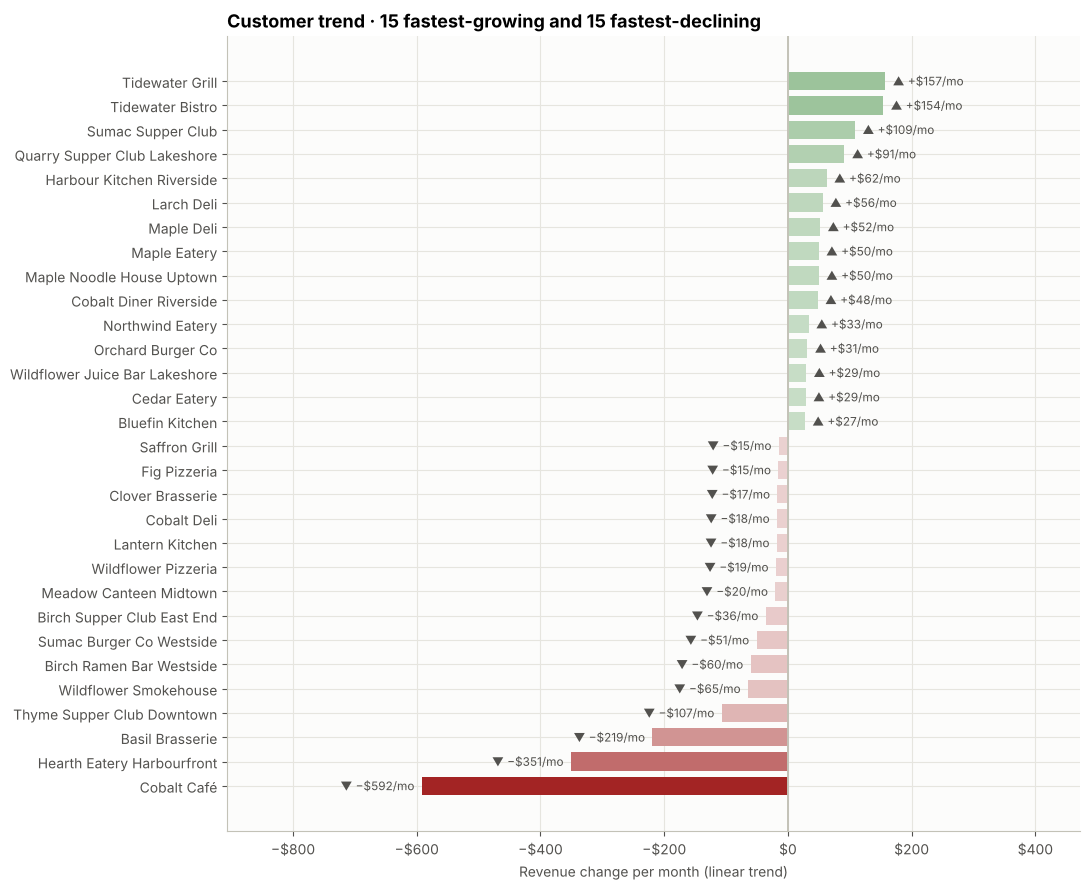

In [21]:
# Diverging bar chart: growth right in green, decline left in red; deeper colour = steeper slope.
if slopes.empty:
    print(f"Needs at least {TF['trend_min']} full {TF['period']}s of data with purchases in most of them; this export has {P}.")
show = pd.concat([slopes.head(15), slopes.tail(15)]) if len(slopes) > 30 else slopes
show = show[~show.index.duplicated()].sort_values()
mx = max(abs(show).max(), 1) if len(show) else 1
def tint(v):
    deep = np.array(mcolors.to_rgb(GOOD_DEEP if v >= 0 else BAD_DEEP))
    k = 0.18 + 0.82 * min(1, abs(v) / mx)
    return tuple(np.array(mcolors.to_rgb(SURFACE)) * (1 - k) + deep * k)
per = {'week': '/wk', 'month': '/mo'}[TF['period']]
fig, ax = plt.subplots(figsize=(11, max(4, len(show) * 0.3))) if len(show) else (None, None)
if len(show): ax.barh(show.index, show.values, color=[tint(v) for v in show.values], height=0.75)
if len(show):
    for i, v in enumerate(show.values):
        ax.text(v + (mx * 0.02 if v >= 0 else -mx * 0.02), i, f"{'▲ +' if v >= 0 else '▼ −'}{compact(abs(v))}{per}",
                va='center', ha='left' if v >= 0 else 'right', fontsize=8.5, color=INK2)
    lo_, hi_ = min(0, show.min()), max(0, show.max()); pad = max(hi_ - lo_, 1) * 0.42   # room for the labels
    ax.axvline(0, color='#c3c2b7', lw=1.4); ax.set_xlim(lo_ - pad if lo_ < 0 else 0, hi_ + pad if hi_ > 0 else 0)
    ax.xaxis.set_major_formatter(money_axis); ax.set_xlabel(f"Revenue change per {TF['period']} (linear trend)")
    ax.set_title(f"Customer trend · {'15 fastest-growing and 15 fastest-declining' if len(slopes) > 30 else 'all customers with enough history'}")
    plt.tight_layout(); plt.show()

### 7.3 Needs attention

A customer is listed when their **average revenue per period recently** is at least `ATTENTION_THRESHOLD` (25%) **below their baseline**. The windows come from the timeframe:
- **sequential:** the last 2 / 4 weeks or 3 months against the same number before;
- **multi-year:** the last 3 months against **the same 3 months a year earlier**, so seasonal swings don't raise alarms.

Customers who **stopped paying by card** are not listed (they pay another way now). For customers who took a **break** from card, periods spent wholly off card are left out of both averages.

The list is sorted by **shortfall** (baseline − recent) in dollars, because a big account slipping matters more than a small one.

In [22]:
r_idx = b_idx = None; kind = 'sequential'
if TF['yoy'] and P >= TF['recent'] + 12:
    r_idx = list(range(P - TF['recent'], P)); b_idx = [i - 12 for i in r_idx]; kind = 'same months a year earlier'
elif P >= 2:
    R = TF['recent'] if P >= TF['recent'] + TF['base'] else max(1, P // 2)
    Bn = min(TF['base'], P - R)
    r_idx = list(range(P - R, P)); b_idx = list(range(P - R - Bn, P - R))
if r_idx:
    rng = lambda idx: (f"{track.start[idx[0]]:%d %b}–{track.end[idx[-1]]:%d %b %Y}" if TF['period'] == 'week'
                       else f"{track.label[idx[0]]} – {track.label[idx[-1]]}")
    rows = []
    for cust, ys in series.iterrows():
        if cust in stopped_set: continue                                  # paying another way now
        b_on = [i for i in b_idx if not off_card(cust, i)]                # on-card periods only
        r_on = [i for i in r_idx if not off_card(cust, i)]
        if not b_on or not r_on: continue
        rows.append({'customer': cust, 'base': ys[b_on].mean(), 'recent': ys[r_on].mean()})
    avgs = pd.DataFrame(rows, columns=['customer', 'base', 'recent']).set_index('customer')
    base_avg, recent_avg = avgs.base, avgs.recent
    chg = (recent_avg - base_avg) / base_avg.where(base_avg > 0)
    last_day = named_sales.groupby('customer').day.max().reindex(avgs.index)
    attention = pd.DataFrame({'baseline': base_avg / 100, 'recent': recent_avg / 100, 'change': chg,
                              'shortfall': (base_avg - recent_avg) / 100, 'days since': (date_to - last_day).dt.days})
    attention = attention[attention.change <= -ATTENTION_THRESHOLD].sort_values(['shortfall'], ascending=False)
    print(f"Recent = {rng(r_idx)}; baseline = {rng(b_idx)} ({kind}). {len(attention)} customers are at least "
          f"{ATTENTION_THRESHOLD:.0%} below baseline, {money(attention.shortfall.sum())} per {TF['period']} in total.")
    if attention.empty: print('✓ Nobody is that far below their baseline.')
    display(attention.assign(baseline=attention.baseline.map(money), recent=attention.recent.map(money),
                             change=attention.change.map(lambda v: '▼ ' + signed_pct(v, 0)), shortfall=attention.shortfall.map(money)).head(25))

Recent = Jul '25 – Sep '25; baseline = Apr '25 – Jun '25 (sequential). 19 customers are at least 25% below baseline, $10,008 per month in total.


,baseline,recent,change,shortfall,days since
customer,,,,,
Northwind Eatery,"$4,584","$1,869",▼ −59%,"$2,714",6
Basil Brasserie,"$7,007","$4,731",▼ −32%,"$2,275",9
Cobalt Café,"$3,148","$1,892",▼ −40%,"$1,256",0
Hearth Eatery Harbourfront,"$2,680","$1,698",▼ −37%,$981,2
Thyme Supper Club Downtown,"$1,160",$683,▼ −41%,$477,25
Sparrow Diner,"$1,070",$684,▼ −36%,$386,19
Sumac Burger Co Westside,$651,$338,▼ −48%,$313,44
Basil Tavern Downtown,$629,$363,▼ −42%,$266,4
Clover Supper Club,$656,$392,▼ −40%,$263,14


### 7.4 Payment cadence and overdue customers

**Usual gap** = the average number of days between a customer's distinct card-payment days, for customers **still paying by card**. Breaks of 60+ days are left out, because that time was spent paying another way, and at least 2 on-card gaps are needed. Most customers sit near 7 days.

A customer is **overdue** when the days since their last card payment are at least twice their own usual gap, and at least 7. Because stopped customers are excluded, overdue always means under 60 days. These customers still count as card payers but are late against their own habit, so this is the list worth a call. At 60 days they move to *stopped paying by card* (7.1).

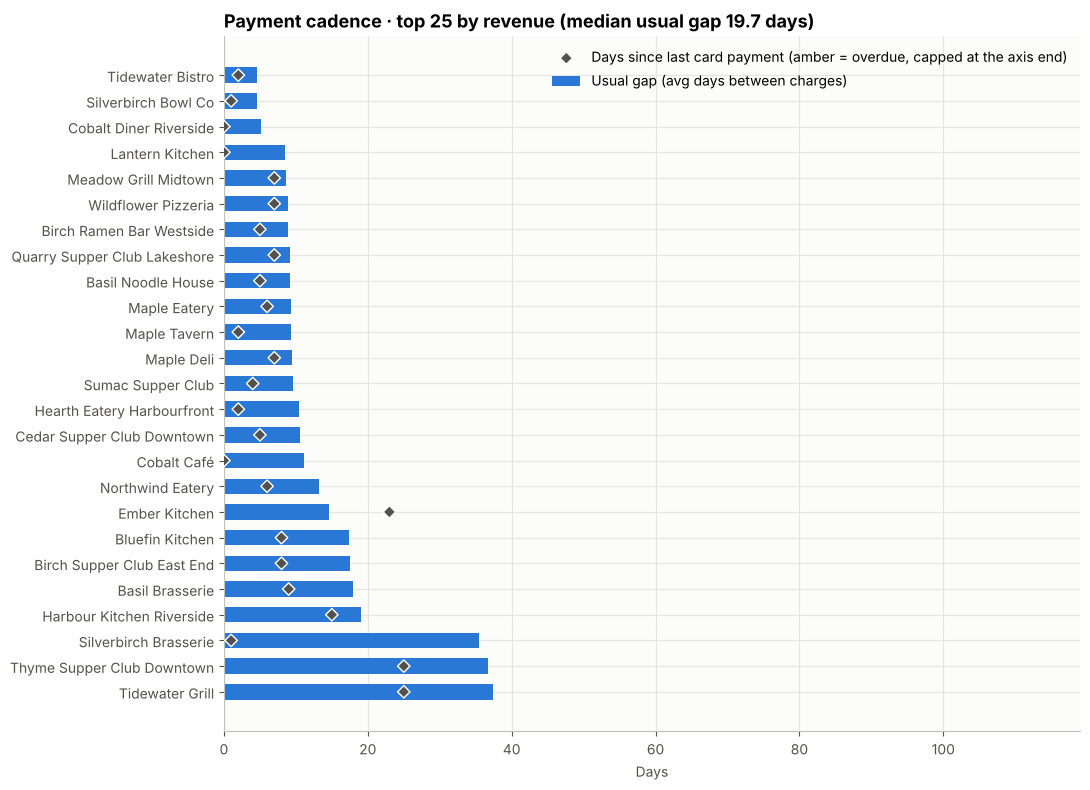

Overdue against their own rhythm (under 60 days, at least 2× their usual gap): 0 customers


,usual_gap,since,x_usual,gross
customer,,,,


In [23]:
gaps = {}
for cust, d in pay_days.items():
    if cust in stopped_set: continue                                      # not paying by card any more
    on_card = [(b - a).days for a, b in zip(d, d[1:]) if (b - a).days < CARD_STOP_DAYS]  # breaks left out
    if len(on_card) >= 2:
        gaps[cust] = float(np.mean(on_card))
cust_tbl = named_sales.groupby('customer').agg(gross=('cents', 'sum'), charges=('cents', 'size'), last=('day', 'max'))
cust_tbl['since'] = (date_to - cust_tbl['last']).dt.days
cadence = cust_tbl.join(pd.Series(gaps, name='usual_gap'), how='inner')
cadence['x_usual'] = cadence.since / cadence.usual_gap
overdue = cadence[(cadence.since >= 7) & (cadence.x_usual >= 2)].sort_values('gross', ascending=False)

# Chart: usual gap (bars) and days since the last charge (diamonds) for the top 25 customers by revenue.
top = cadence.sort_values('gross', ascending=False).head(25).sort_values('usual_gap', ascending=False)
if top.empty: print('No customer has 3 or more charge days yet, so there is no usual gap to show.')
cap = max(28, int(np.ceil(top.usual_gap.max() * 3 / 7) * 7)) if len(top) else 28
fig, ax = plt.subplots(figsize=(11, 8)) if len(top) else (None, None)
if len(top):
    ax.barh(top.index, top.usual_gap, color=ACCENT, height=0.6, label='Usual gap (avg days between charges)')
    od = (top.since >= 7) & (top.x_usual >= 2)
    ax.scatter(np.minimum(top.since, cap), top.index, marker='D', s=40, color=np.where(od, WARN, INK2), zorder=3,
               edgecolor='white', label='Days since last card payment (amber = overdue, capped at the axis end)')
    ax.set_xlim(0, cap); ax.set_xlabel('Days'); ax.legend(loc='upper right', frameon=False)
    ax.set_title(f"Payment cadence · top 25 by revenue (median usual gap {np.median(list(gaps.values())):.1f} days)")
    plt.tight_layout(); plt.show()
print(f"Overdue against their own rhythm (under {CARD_STOP_DAYS} days, at least 2× their usual gap): {len(overdue)} customers")
display(overdue.assign(gross=overdue.gross.div(100).map(money), usual_gap=overdue.usual_gap.round(1), x_usual=overdue.x_usual.round(1))
        [['usual_gap', 'since', 'x_usual', 'gross']].head(15))

## 8. Customers

### 8.1 Top 15 by revenue (bar chart, not a pie)

Horizontal bars sorted by gross revenue, labelled with dollar values. A bar chart replaces the original pie chart because lengths compare far more accurately than slice angles. The **One-Time Manual Charge** aggregate is hatched grey and marked †, because it adds up unrelated one-off cards and isn't a customer.

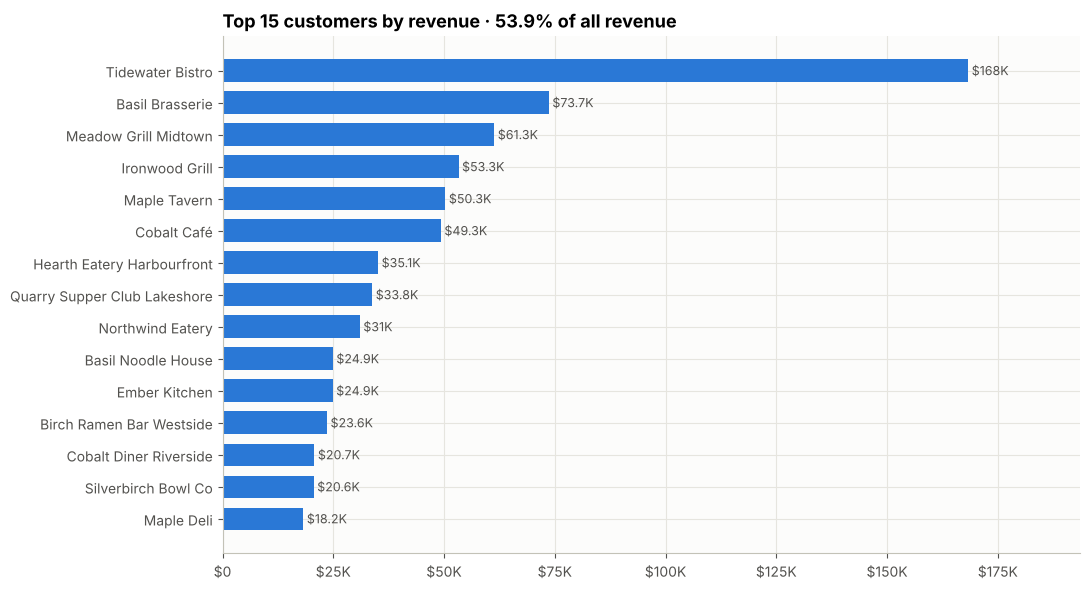

In [24]:
by_cust = sales.groupby('customer').agg(gross=('cents', 'sum'), count=('cents', 'size'), one_time=('one_time', 'first'))
top15 = by_cust.assign(name=by_cust.index).sort_values(['gross', 'name'], ascending=[False, True]).head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 6))
ax.barh([n + (' †' if o else '') for n, o in zip(top15.index, top15.one_time)], top15.gross / 100, height=0.7,
        color=[GREY if o else ACCENT for o in top15.one_time], hatch=['///' if o else '' for o in top15.one_time])
for i, v in enumerate(top15.gross / 100):
    ax.text(v, i, ' ' + compact(v), va='center', fontsize=9, color=INK2)
ax.xaxis.set_major_formatter(money_axis); ax.set_xlim(0, top15.gross.max() / 100 * 1.15)
ax.set_title(f"Top 15 customers by revenue · {pct(top15.gross.sum() / totals['gross'])} of all revenue")
plt.tight_layout(); plt.show()

### 8.2 Revenue concentration (Pareto curve)

Customers are ranked by revenue, and the cumulative share of total revenue is plotted as each is added. The steeper the early rise, the more the business depends on a few accounts. **Top-5 share above 25% is flagged as a risk**: losing one of them would hurt. The one-time aggregate is placed last, because it isn't a single account and must not count towards the top 5.

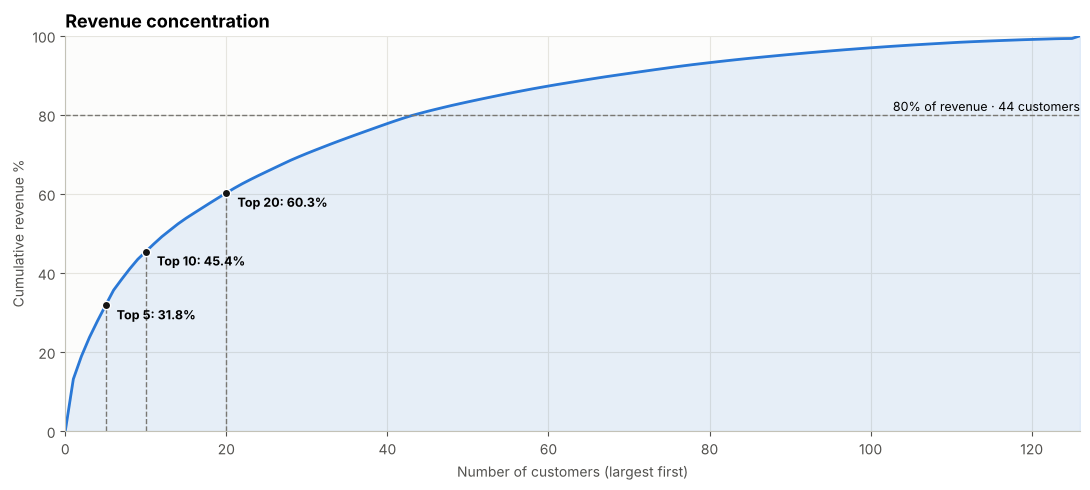

Top 5 hold 31.8% of revenue (⚠ CONCENTRATION RISK: above the 25% guideline); top 10 45.4%; top 20 60.3%; 44 customers make 80%.


In [25]:
named_rank = by_cust[~by_cust.one_time].assign(name=lambda t: t.index).sort_values(['gross', 'name'], ascending=[False, True])
order = pd.concat([named_rank, by_cust[by_cust.one_time].assign(name=ONE_TIME)])
cum = order.gross.cumsum() / totals['gross'] * 100
share = lambda k: named_rank.gross.head(k).sum() / totals['gross']
n80 = int((cum.values >= 80).argmax()) + 1

fig, ax = plt.subplots(figsize=(11, 5))
xs = np.arange(0, len(cum) + 1); ys = np.r_[0, cum.values]
ax.plot(xs, ys, color=ACCENT, lw=2); ax.fill_between(xs, ys, color=ACCENT, alpha=0.1)
for k in (5, 10, 20):
    if k < len(cum):
        ax.plot([k, k], [0, cum.iloc[k - 1]], ls='--', color=MUTED, lw=1)
        ax.plot(k, cum.iloc[k - 1], 'o', color=INK, ms=6, mec='white')
        ax.annotate(f"Top {k}: {cum.iloc[k - 1]:.1f}%", (k, cum.iloc[k - 1]), xytext=(8, -10), textcoords='offset points', fontsize=9, fontweight='bold')
ax.axhline(80, ls='--', color=MUTED, lw=1); ax.text(len(cum), 81, f"80% of revenue · {n80} customers", ha='right', fontsize=9)
ax.set_ylim(0, 100); ax.set_xlim(0, len(cum)); ax.set_xlabel('Number of customers (largest first)'); ax.set_ylabel('Cumulative revenue %')
ax.set_title('Revenue concentration')
plt.tight_layout(); plt.show()
risk = '⚠ CONCENTRATION RISK: above the 25% guideline' if share(5) > 0.25 else '✓ below the 25% guideline'
print(f"Top 5 hold {pct(share(5))} of revenue ({risk}); top 10 {pct(share(10))}; top 20 {pct(share(20))}; {n80} customers make 80%.")

### 8.3 Average revenue per active week or month (top 20)

This shows **how big each customer is when they buy**: revenue ÷ the number of weeks (exports up to ~6 months) or months with at least one successful charge.

The original notebook divided every customer's total by the *same* number of months. That made a customer who joined in month 9 look tiny, because they were averaged over 12 months.

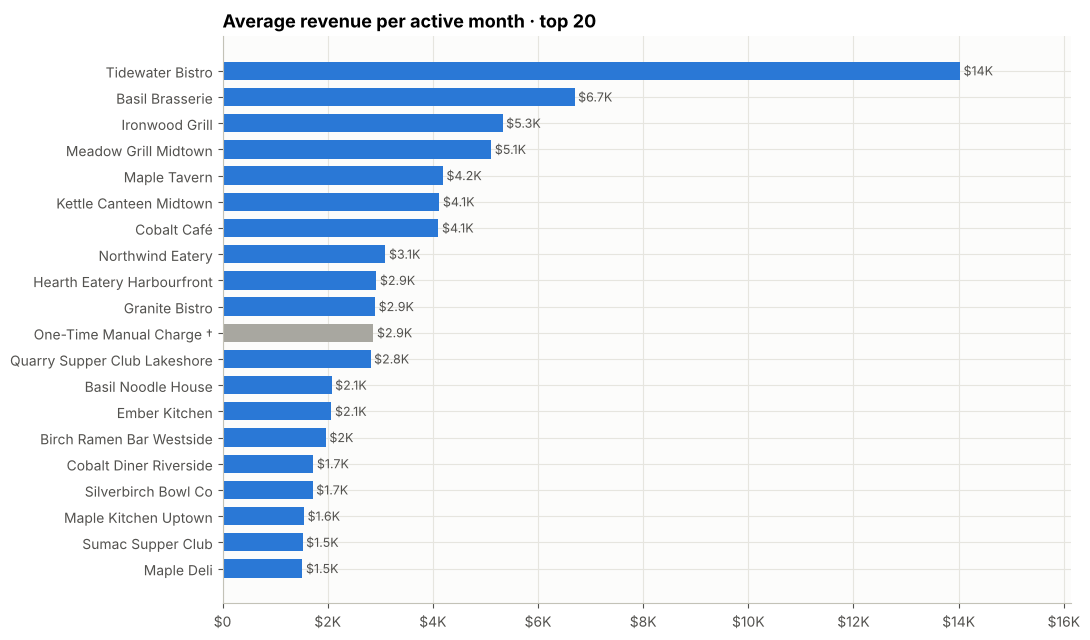

In [26]:
pfreq = 'W-SUN' if TF['period'] == 'week' else 'M'
active = sales.assign(p=sales.day.dt.to_period(pfreq)).groupby('customer').p.nunique()
per_active = (by_cust.gross / active).rename('avg').to_frame().join(by_cust.one_time).assign(active=active, name=lambda t: t.index)
per_active = per_active.sort_values(['avg', 'name'], ascending=[False, True]).head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 6.5))
ax.barh([n + (' †' if o else '') for n, o in zip(per_active.index, per_active.one_time)], per_active.avg / 100, height=0.7,
        color=[GREY if o else ACCENT for o in per_active.one_time])
for i, v in enumerate(per_active.avg / 100):
    ax.text(v, i, ' ' + compact(v), va='center', fontsize=9, color=INK2)
ax.xaxis.set_major_formatter(money_axis); ax.set_xlim(0, per_active.avg.max() / 100 * 1.15)
ax.set_title(f"Average revenue per active {TF['period']} · top 20")
plt.tight_layout(); plt.show()

## 9. Customer segments (RFM)

- **R**ecency = days since the last successful charge (fewer is better)
- **F**requency = number of successful charges
- **M**onetary = gross revenue

Each is scored **1–4 by quartile** and summed (3–12): **High-Value Regular** ≥ 10, **Loyal** 7–9, **At Risk** 5–6, **Dormant** ≤ 4. Named customers only.

Ranks are taken with `rank(method='first')` **before** the quartile cut on all three measures. The original applied it to F and M but not R: many customers share the same recency, so `pd.qcut` on raw recency can collapse bins or fail. Ties are broken by name.

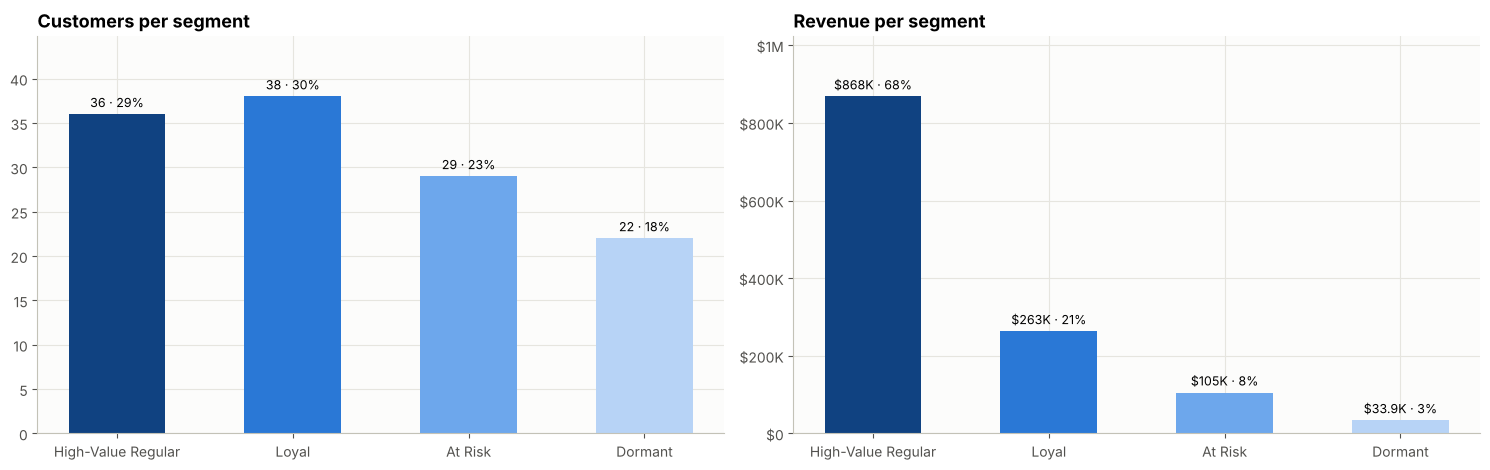

High-Value Regulars are 29% of customers but bring in 68% of revenue.


,segment,recency,frequency,monetary,R,F,M,score
customer,,,,,,,,
Tidewater Bistro,High-Value Regular,2,79,"$168,307",4,4,4,12
Basil Brasserie,High-Value Regular,9,20,"$73,654",3,3,4,10
Meadow Grill Midtown,High-Value Regular,7,42,"$61,339",3,4,4,11
Ironwood Grill,Loyal,60,32,"$53,269",1,4,4,9
Maple Tavern,High-Value Regular,2,38,"$50,300",4,4,4,12
Cobalt Café,High-Value Regular,0,33,"$49,287",4,4,4,12
Hearth Eatery Harbourfront,High-Value Regular,2,35,"$35,120",4,4,4,12
Quarry Supper Club Lakeshore,High-Value Regular,7,39,"$33,789",3,4,4,11
Northwind Eatery,High-Value Regular,6,24,"$30,990",3,4,4,11


In [27]:
rfm = named_sales.groupby('customer').agg(last=('day', 'max'), frequency=('cents', 'size'), monetary=('cents', 'sum')).sort_index()
assert len(rfm) >= 4, 'RFM needs at least 4 named customers with a successful charge.'
rfm['recency'] = (date_to - rfm['last']).dt.days
rfm['monetary'] = rfm.monetary / 100
rfm['R'] = pd.qcut(rfm.recency.rank(method='first'), 4, labels=[4, 3, 2, 1]).astype(int)
rfm['F'] = pd.qcut(rfm.frequency.rank(method='first'), 4, labels=[1, 2, 3, 4]).astype(int)
rfm['M'] = pd.qcut(rfm.monetary.rank(method='first'), 4, labels=[1, 2, 3, 4]).astype(int)
rfm['score'] = rfm.R + rfm.F + rfm.M
SEGMENTS = ['High-Value Regular', 'Loyal', 'At Risk', 'Dormant']
rfm['segment'] = np.select([rfm.score >= 10, rfm.score >= 7, rfm.score >= 5], SEGMENTS[:3], default='Dormant')
seg = rfm.groupby('segment').agg(customers=('score', 'size'), revenue=('monetary', 'sum')).reindex(SEGMENTS, fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for ax, col, fmt, title in ((axes[0], 'customers', lambda v: f"{v:.0f}", 'Customers per segment'),
                            (axes[1], 'revenue', compact, 'Revenue per segment')):
    b = ax.bar(seg.index, seg[col], color=SEG_COLORS, width=0.55)
    tot = seg[col].sum()
    ax.bar_label(b, labels=[f"{fmt(v)} · {v / tot:.0%}" for v in seg[col]], padding=3, fontsize=9)
    ax.set_title(title); ax.set_ylim(0, seg[col].max() * 1.18)
    if col == 'revenue': ax.yaxis.set_major_formatter(money_axis)
plt.tight_layout(); plt.show()
hv = seg.loc['High-Value Regular']
print(f"High-Value Regulars are {hv.customers / seg.customers.sum():.0%} of customers but bring in {hv.revenue / seg.revenue.sum():.0%} of revenue.")
display(rfm.sort_values('monetary', ascending=False).assign(monetary=lambda t: t.monetary.map(money))
        [['segment', 'recency', 'frequency', 'monetary', 'R', 'F', 'M', 'score']].head(15))

## 10. Customers starting to pay by card

An export starts **part-way through every customer relationship**. A regular who simply hadn't paid yet in the first days was already a card payer. So a customer counts as **starting to pay by card** only when their first card payment in the export comes after a settling-in window: 35 days for exports of a few months, 45 days for a year or more. In the 2025 export about 95–98% of customers paid at least every 35 days, so the window catches most regulars. It can't catch a customer on a longer agreement cycle or one coming back after a break.

**This is not the same as a new customer.** The export only shows card payments, so a first card payment can also be:
- an existing account moving from EFT to card;
- a customer coming back to card after a long break that began before the export.

One export can't tell these apart; that needs the customer list or earlier exports. Exports of a few weeks can't separate starters from existing card payers at all, so only active customers are shown.

The original counted *everyone* in the first month as new. The line is the running count of unique card-paying customers.

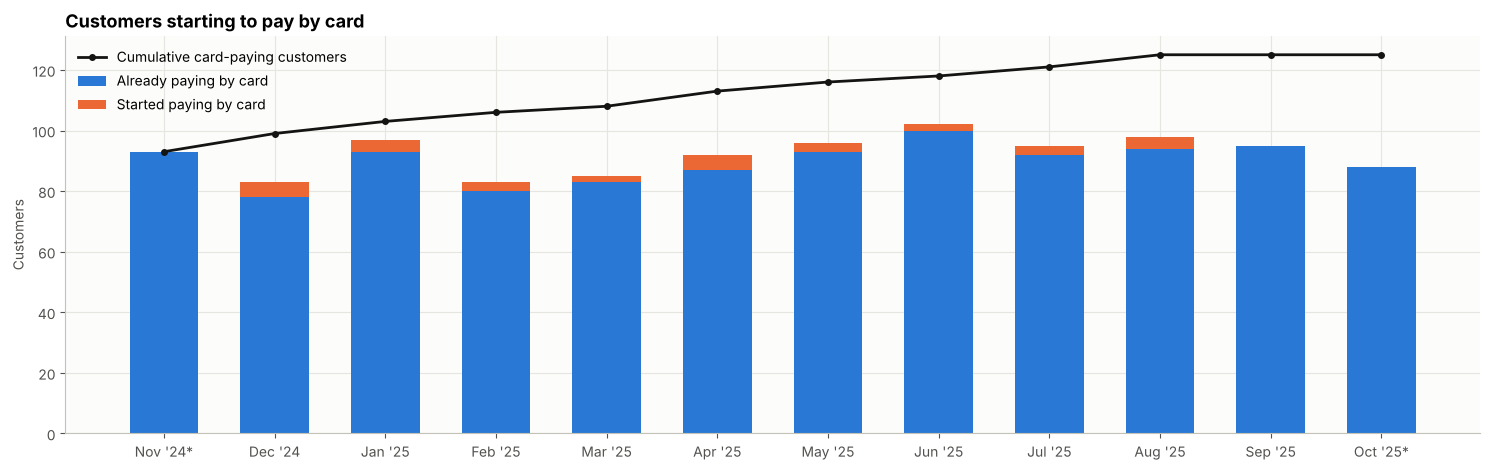

Started paying by card (first card payment after day 45): 31; unique card-paying customers: 125


In [28]:
new_known = TF['warmup'] is not None and span_days > TF['warmup']
warm_end = date_from + pd.Timedelta(days=(TF['warmup'] or 0) - 1) if new_known else date_to
first_bucket = {c: (bucket_of(pd.Series([d]))[0] if d > warm_end else -1) for c, d in first_day.items()}
active_sets = named_sales.assign(b=bucket_of(named_sales.day)).groupby('b').customer.unique()
acq = pd.DataFrame(index=buckets.index, columns=['new', 'existing', 'cumulative'], data=0)
seen = set()
for i in buckets.index:
    names = active_sets.get(i, [])
    acq.loc[i, 'new'] = sum(first_bucket[n] == i for n in names)
    acq.loc[i, 'existing'] = len(names) - acq.loc[i, 'new']
    seen.update(names); acq.loc[i, 'cumulative'] = len(seen)

fig, ax = plt.subplots(figsize=(15, 4.8))
ax.bar(x, acq.existing, width=0.62, color=ACCENT, label='Already paying by card' if new_known else 'Paying by card')
if new_known:
    ax.bar(x, acq.new, bottom=acq.existing, width=0.62, color=ORANGE, label='Started paying by card')
ax.plot(x, acq.cumulative, color=INK, marker='o', ms=4, lw=2, label='Cumulative card-paying customers')
ax.set_xticks(x, buckets.label, rotation=0 if len(x) <= 14 else 45, ha='center' if len(x) <= 14 else 'right')
ax.set_ylabel('Customers'); ax.legend(frameon=False, loc='upper left'); ax.set_title('Customers starting to pay by card')
plt.tight_layout(); plt.show()
print(f"Started paying by card (first card payment after day {TF['warmup']}): {acq.new.sum()}; unique card-paying customers: {acq.cumulative.iloc[-1]}"
      if new_known else "Too little history to tell who started paying by card.")

## 11. Risk and operations

### 11.1 Failure rate by customer (≥ 10 attempts)

Failure rate = failed ÷ all charge attempts for the customer. Only customers with **at least 10 attempts** are ranked, so one failure on a two-order account doesn't top the chart. The original notebook's chart title said "min. 3" while its code used 10; 10 is used here, and the chart says so. A high rate usually means a card on file that's expired, over its limit or being declined.

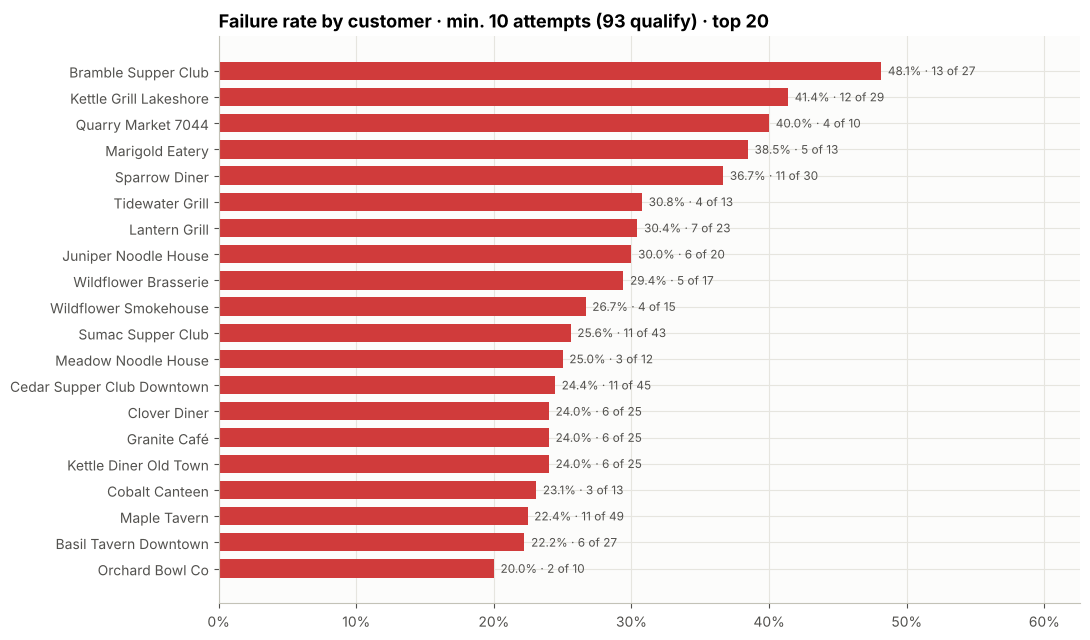

In [29]:
per = attempts.groupby('customer').agg(attempts=('status', 'size'), failed=('status', lambda s: s.eq('Failed').sum()), one_time=('one_time', 'first'))
fr = per[(per.attempts >= 10) & (per.failed > 0)].assign(rate=lambda t: t.failed / t.attempts, name=lambda t: t.index)
fr = fr.sort_values(['rate', 'failed', 'name'], ascending=[False, False, True]).head(20).iloc[::-1]
if fr.empty:
    print(f"No customer with 10 or more attempts has a failed charge ({(per.attempts >= 10).sum()} customers have 10+ attempts).")
fig, ax = plt.subplots(figsize=(11, 6.5)) if len(fr) else (None, None)
if len(fr):
    ax.barh([n + (' †' if o else '') for n, o in zip(fr.index, fr.one_time)], fr.rate * 100, color=BAD, height=0.7)
    for i, (r, f_, a) in enumerate(zip(fr.rate, fr.failed, fr.attempts)):
        ax.text(r * 100, i, f"  {r * 100:.1f}% · {f_} of {a}", va='center', fontsize=8.5, color=INK2)
    ax.set_xlim(0, fr.rate.max() * 130); ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.0f}%"))
    ax.set_title(f"Failure rate by customer · min. 10 attempts ({(per.attempts >= 10).sum()} qualify) · top 20")
    plt.tight_layout(); plt.show()

### 11.2 Card type mix, failure rate by card type, and decline reasons

- **Card mix** is the share of gross revenue by network, shown as a donut with dollar values. Processing fees differ by network, so a shift in the mix changes what card sales cost.
- **Failure rate by card type** shows whether one network declines more than the others.
- **Decline reasons** come from the processor's status message.

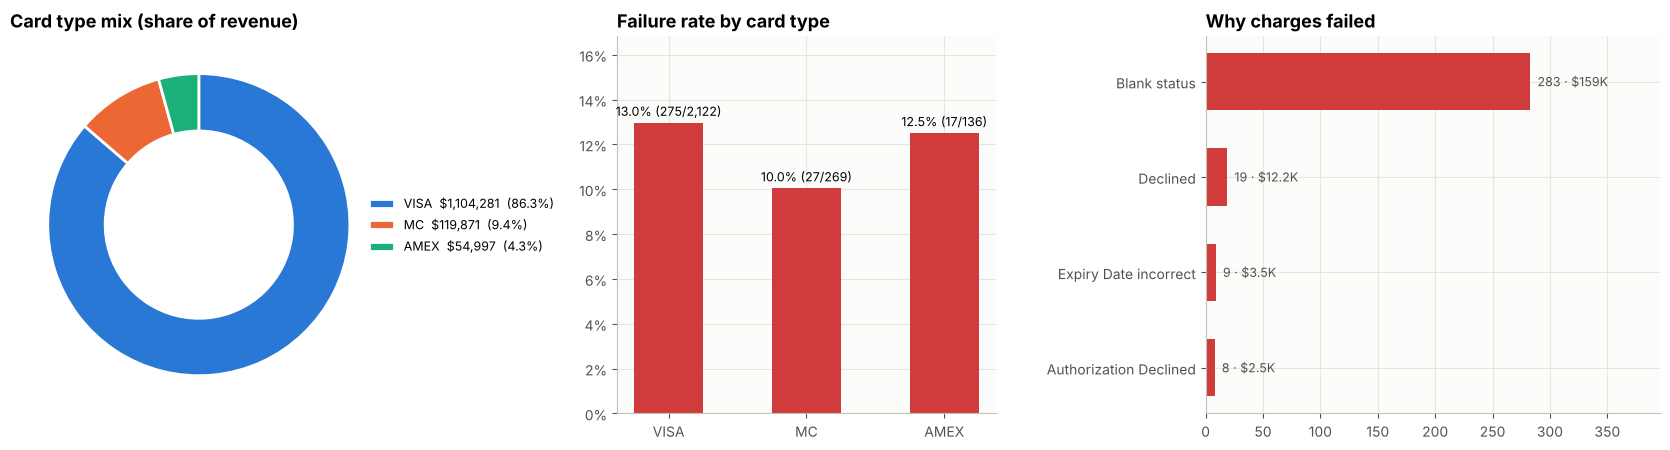

In [30]:
CARD_COLORS = {'VISA': ACCENT, 'MC': ORANGE, 'AMEX': AQUA}
cards = attempts.groupby('card').agg(attempts=('status', 'size'), failed=('status', lambda s: s.eq('Failed').sum()))
cards = cards.join(sales.groupby('card').agg(revenue=('cents', 'sum'), charges=('cents', 'size'))).fillna(0)
cards = cards.sort_values(['revenue', 'attempts'], ascending=False)
reasons = failed.groupby('reason').agg(count=('cents', 'size'), cents=('cents', 'sum')).sort_values('count')

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), gridspec_kw={'width_ratios': [1.1, 1, 1.2]})
mix = cards[cards.revenue > 0]
axes[0].pie(mix.revenue, colors=[CARD_COLORS.get(c, GREY) for c in mix.index], startangle=90, counterclock=False,
            wedgeprops=dict(width=0.38, edgecolor='white', linewidth=2))
axes[0].legend([f"{c}  {money(v / 100)}  ({v / mix.revenue.sum():.1%})" for c, v in mix.revenue.items()], loc='center left',
               bbox_to_anchor=(0.92, 0.5), frameon=False, fontsize=9)
axes[0].set_title('Card type mix (share of revenue)')
rate = cards.failed / cards.attempts * 100
b = axes[1].bar(cards.index, rate, color=BAD, width=0.5)
axes[1].bar_label(b, labels=[f"{r:.1f}% ({int(f_)}/{int(a):,})" for r, f_, a in zip(rate, cards.failed, cards.attempts)], fontsize=9, padding=3)
axes[1].set_ylim(0, max(rate.max(), 1) * 1.3); axes[1].set_title('Failure rate by card type')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.0f}%"))
if len(reasons):
    axes[2].barh(reasons.index, reasons['count'], color=BAD, height=0.6)
    for i, (n_, c_) in enumerate(zip(reasons['count'], reasons.cents)):
        axes[2].text(n_, i, f"  {n_} · {compact(c_ / 100)}", va='center', fontsize=9, color=INK2)
    axes[2].set_xlim(0, reasons['count'].max() * 1.4)
else:
    axes[2].text(0.5, 0.5, 'No failed charges ✓', ha='center', transform=axes[2].transAxes); axes[2].set_axis_off()
axes[2].set_title('Why charges failed')
plt.tight_layout(); plt.show()

### 11.3 Retry chains and voided transactions

Retry statistics come from section 2.6. **"Possibly paid another way"** is context only, not part of the recovery rate: it counts unrecovered failures where the same customer had a successful charge for a *different* amount or card within 7 days.

**Voids** are admin cancellations. They are never revenue but are counted as attempts in the success rate. Most are $1.00 card-on-file tests, which the void comment confirms.

In [31]:
unrec = scope.loc[unrecovered]
def paid_within_7_days(r):
    # Context only: did this customer have any other successful charge in the 7 days after the failure?
    s = named_sales[named_sales.customer.eq(r.customer)]
    later = (s.day > r.day) | ((s.day == r.day) & (s.second > r.second))
    return bool((later & ((s.day - r.day).dt.days <= 7)).any())
later_paid = sum(paid_within_7_days(r) for r in unrec[~unrec.one_time].itertuples())
retry_summary = pd.Series({
    'failed charges': len(failed[failed.cents > 0]),
    'retry chains': len(chains),
    'groups with a failure and a success (original definition)': mixed_groups,
    'recovered failures': len(recovered_rows),
    'retry recovery rate': pct(len(recovered_rows) / len(failed[failed.cents > 0])) if len(failed) else '—',
    'average days, first failure → success': round(chains.days.mean(), 1) if len(chains) else '—',
    'chains that took over 14 days (may be a new order)': int((chains.days > 14).sum()) if len(chains) else 0,
    'recovered revenue': money(chains.amount.sum()) if len(chains) else '$0',
    'not recovered': f"{len(unrecovered)} ({money(unrec.cents.sum() / 100)})",
    'possibly paid another way (context only)': later_paid,
}, name='value')
display(retry_summary.to_frame())
if len(chains):
    display(chains.attempts.value_counts().sort_index().rename_axis('attempts in chain').to_frame('chains'))

voids = voided.groupby('customer').agg(voids=('cents', 'size'), amount=('cents', 'sum'),
                                       comments=('void_note', lambda s: '; '.join(sorted(set(s) - {''})))).sort_values(['amount', 'voids'], ascending=False)
print(f"{len(voided)} voided transactions totalling {money(voided.cents.sum() / 100, cents=True)}; "
      f"{(voided.cents == 100).sum()} of them are $1.00 card tests")
display(voids.assign(amount=voids.amount.div(100).map(lambda v: money(v, cents=True))).head(10))

,value
failed charges,319
retry chains,118
groups with a failure and a success (original definition),113
recovered failures,140
retry recovery rate,43.9%
"average days, first failure → success",8.3
chains that took over 14 days (may be a new order),11
recovered revenue,"$77,657"
not recovered,"179 ($88,152)"
possibly paid another way (context only),28


,chains
attempts in chain,
2,99
3,16
4,3


28 voided transactions totalling $1,388.67; 25 of them are $1.00 card tests


,voids,amount,comments
customer,,,
Birch Ramen Bar Westside,2,$618.31,Duplicate keyed in error; test
Sparrow Diner,1,$474.53,Order cancelled
Marigold Eatery,1,$271.83,Customer paying by e-transfer
Birch Canteen,1,$1.00,Test
Bramble Deli,1,$1.00,test
Clover Diner,1,$1.00,test
Cobalt Bakery,1,$1.00,TEST
Cobalt Deli,1,$1.00,test
Ember Bowl Co,1,$1.00,TEST


## 12. Data quality

This panel is what makes the numbers above trustworthy. It records every row that was read, rejected, relabelled or flagged.

In [32]:
dups = scope[scope.status.eq('Batched') & scope.cents.ne(0)].groupby(['customer', 'cents', 'card', 'day']).filter(lambda g: len(g) > 1)
dq = pd.DataFrame([
    ('Rows parsed', f"{len(df):,} of {len(raw):,}", ''),
    ('Unparseable dates', bad_date.sum(), 'excluded'),
    ('Unreadable amounts', bad_amount.sum(), 'excluded (amount must be whole cents)'),
    ('Unrecognised statuses', unknown_status.sum(), 'excluded'),
    ('Date format', ', '.join(df.date_format.unique()), 'detected automatically'),
    ('Blank customer names relabelled', df.label.eq(ONE_TIME).sum(), f"{manual_hit.sum()} assigned to a customer by cardholder"),
    ('Blank statuses relabelled', blank_status_kept, 'blank status = failed attempt'),
    ('"Failed – Result …" statuses', suffixed_failed_kept, 'normalised to Failed; message kept as reason'),
    ('Negative amounts (refunds / credits)', len(negatives), money(negatives.cents.sum() / 100, cents=True)),
    ('Zero-amount transactions', len(zeros), 'should not exist: review'),
    ('Same-day exact duplicates', dups.groupby(['customer', 'cents', 'card', 'day']).ngroups, 'same customer, amount, card, date, both successful'),
    ('Retry chains detected', len(chains), f"{mixed_groups} groups contain both a failure and a success"),
    ('Customer names grouped', members.map(len).sum() if len(members) else 0, f"into {len(members)} customers, from your groups file"),
    ('Currencies', ', '.join(f"{k} ({v:,})" for k, v in df.currency.value_counts().items()), 'mixed currencies would be summed as-is'),
    ('Card types', ' · '.join(f"{k} {v:,}" for k, v in df.card.value_counts().items()), ''),
], columns=['check', 'count', 'note']).set_index('check')
display(dq)

,count,note
check,,
Rows parsed,"2,531 of 2,531",
Unparseable dates,0,excluded
Unreadable amounts,0,excluded (amount must be whole cents)
Unrecognised statuses,0,excluded
Date format,DD/MM/YYYY (day first),detected automatically
Blank customer names relabelled,8,2 assigned to a customer by cardholder
Blank statuses relabelled,283,blank status = failed attempt
"""Failed – Result …"" statuses",36,normalised to Failed; message kept as reason
Negative amounts (refunds / credits),4,"−$1,559.33"


## 13. What changed from the original notebook, and why

| step | original notebook | this notebook / the dashboard | why |
|---|---|---|---|
| Status | `pd.Categorical` with 3 categories | explicit normalisation; reason kept | `Failed - Result […]` became `NaN`, so failed charges looked like missing data |
| Dates | `DD/MM/YYYY HH:MM` only | day-first or year-first, explicit | newer exports write `2026-06-30 21:44:36` |
| Customers | one name = one customer | customer groups (names + manual charges by cardholder) | the processor stores each card under its own name |
| Duplicates | same customer + amount + card | + same date + both successful | order guides make repeated amounts normal |
| Retries | group has any failure and any success | failures followed by a later success, per chain | a success before a failure isn't a recovery |
| Monthly average | total ÷ months in the whole period | total ÷ the customer's active weeks/months | late joiners were understated |
| Trend slope | `linregress` on months with sales, all of 2025 | `polyfit` incl. $0 periods, from the customer's first period, complete periods only (last 12 months for multi-year); periods wholly off card skipped | gaps are information; partial months distort; a break from card isn't a slump |
| Silent customers | not covered | 60+ days without a card payment = stopped paying by card as of that date; left out of trends and Needs attention | it almost always means a switch to EFT or another method, not lost sales |
| Top customers | pie of top 10 | bars of top 15; one-time aggregate tagged | bars compare accurately; the aggregate isn't a customer |
| Concentration | one-time aggregate ranked like a customer | placed last, never in the top 5 | it adds up unrelated one-off cards |
| RFM recency | `qcut` on raw recency | `qcut` on `rank(method='first')` | ties on recency collapse quartile bins |
| New vs returning | everyone new in the first month | "started paying by card": first card payment after a settling-in window | every export starts mid-relationship, and a first card payment can be an existing account |
| Comparisons | month vs month | adapted to the export's length | 3 weeks, 3 months and 3 years need different comparisons |

In [33]:
# Key results: these match the dashboard's tiles and charts for the same file, date range and customer groups.
RESULTS = {
    'timeframe': TF['key'], 'charts grouped by': UNIT, 'span days': span_days,
    'gross revenue': money(totals['gross'] / 100), 'net revenue': money(totals['net'] / 100), 'transactions': totals['count'],
    'average transaction': money(totals['avg'] / 100), 'active customers': totals['activeCustomers'],
    'success rate': pct(totals['successRate']), 'retry recovery rate': pct(totals['recoveryRate']),
    'voided amount': money(totals['voidCents'] / 100), 'top-5 concentration': pct(share(5)),
    'tiles compare': compare['label'] if compare else '—',
    'gross change on tiles': signed_pct(change('gross')) if compare else '—',
    'customers with a trend': len(slopes), 'needs attention': len(attention) if r_idx else '—',
    'stopped paying by card': len(stopped) if span_days > CARD_STOP_DAYS else '—', 'back on card after a break': len(back),
    'overdue against their rhythm': len(overdue), 'RFM segments': seg.customers.to_dict(),
}
pd.Series(RESULTS, name='value').to_frame()

,value
timeframe,long
charts grouped by,month
span days,360
gross revenue,"$1,279,149"
net revenue,"$1,277,589"
transactions,2179
average transaction,$587
active customers,125
success rate,86.3%
retry recovery rate,43.9%
